# Drought-to-flood Europe — structured notebook

This notebook performs a drought→flood Event Coincidence Analysis (ECA) for multiple European rivers/locations and produces the same outputs (tables/files/figures) as the original notebook, but with a clearer structure and less duplicated code.

Sections:
1. Setup & data
2. Helper functions (runoff/SRI/intensity/event extraction)
3. ECA analysis (analytical + Monte Carlo)
4. Copula analysis & figure export


In [ ]:

from google.colab import drive
drive.flush_and_unmount()
drive.mount('/content/drive')


Drive not mounted, so nothing to flush and unmount.
Mounted at /content/drive


In [ ]:
# If running in Colab / fresh environment:
!pip install vinecopulas
!pip install netCDF4


# =========================
# Core scientific stack
# =========================
import os
import io
import copy
import math

import numpy as np
import pandas as pd
import xarray as xr
import netCDF4 as nc

# =========================
# Statistics
# =========================
import scipy.stats as stats
from scipy import stats
from scipy.stats import gamma, norm, kendalltau, binom
from scipy.optimize import fsolve
from scipy.special import gamma as gamma_func
import scipy.integrate as integrate

# =========================
# Plotting / imaging
# =========================
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.lines as mlines
from PIL import Image
import cv2

# =========================
# Copulas
# =========================
import vinecopulas
from vinecopulas.bivariate import *

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.1/45.1 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 72.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 77.4 MB/s eta 0:00:00


## Parameters and river locations

Edit `input_file` if your data is stored elsewhere. The `rivers` structure is used throughout the analysis.

In [ ]:
data.valid_time[first_end]

<xarray.DataArray 'valid_time' ()> Size: 8B
array('2010-01-01T12:00:00.000000000', dtype='datetime64[ns]')
Coordinates:
    surface     float64 8B ...
    valid_time  datetime64[ns] 8B 2010-01-01T12:00:00
Attributes:
    long_name:      time
    standard_name:  time

In [ ]:

# -----------------------------------------------------------------------------
# Parameters & configuration
# -----------------------------------------------------------------------------

# Two equal-length periods (weekly data; indices are used to slice `valid_time`)
first_begin = 0
first_end   = 5479
second_begin = 5480
second_end   = 10958

time_scale = "1W"      # weekly aggregation
n_simulations = 10000  # Monte Carlo simulations in ECA

# Input data (edit to your local path if needed)
input_file ="/content/drive/MyDrive/1. Drougt-to-flood article/2. data/8_maart_european_river_runoff_1994_2024.nc"
#"/content/drive/MyDrive/1. Drougt-to-flood article/2. data/subset/definitive_file_6_04_25.nc"

# -----------------------------------------------------------------------------
# River locations (keep as-is; used throughout the notebook)
# -----------------------------------------------------------------------------
rivers = [
    {
        'river': 'Danube',
        'locations': [
            {'river_location': 'First location', 'village': 'Aschach an der Donau', 'latitude': 48.366381, 'longitude': 14.027309},
            {'river_location': 'Second location', 'village': 'Visegrád', 'latitude': 47.792178, 'longitude': 18.905964},
            {'river_location': 'Third location', 'village': 'Donji Milanovac', 'latitude': 44.474911, 'longitude': 22.155304}
        ]
    },
    {
        'river': 'Dnieper',
        'locations': [
            {'river_location': 'First location', 'village': 'Krementsjoek', 'latitude': 49.054867, 'longitude': 33.413367},
            {'river_location': 'Second location', 'village': 'Dnipro', 'latitude': 48.482640, 'longitude': 35.041132},
            {'river_location': 'Third location', 'village': 'Cherson', 'latitude': 46.635113, 'longitude': 32.635810}
        ]
    },
    {
        'river': 'Rhine',
        'locations': [
            {'river_location': 'First location', 'village': 'Straatsburg', 'latitude': 48.472895, 'longitude': 7.756314},
            {'river_location': 'Second location', 'village': 'Mainz', 'latitude': 49.993896, 'longitude': 8.289450},
            {'river_location': 'Third location', 'village': 'Nijmegen', 'latitude': 51.851323, 'longitude': 5.861785}
        ]
    },
    {
        'river': 'Don',
        'locations': [
            {'river_location': 'First location', 'village': 'Nikolaevskaya', 'latitude': 47.600147, 'longitude': 41.489972},
            {'river_location': 'Second location', 'village': 'Kochetovskaya', 'latitude': 47.570679, 'longitude': 40.841345},
            {'river_location': 'Third location', 'village': 'Rostov - Dov', 'latitude': 47.192214, 'longitude': 39.667721}
        ]
    },
    {
        'river': 'Vistula',
        'locations': [
            {'river_location': 'First location', 'village': 'Łączany', 'latitude': 49.988560, 'longitude': 19.584211},
            {'river_location': 'Second location', 'village': 'Warchau', 'latitude': 52.196415, 'longitude': 21.104997},
            {'river_location': 'Third location', 'village': 'Turon', 'latitude': 53.014320, 'longitude': 18.647809}
        ]
    },
    {
        'river': 'Po',
        'locations': [
            {'river_location': 'First location', 'village': 'Turijn', 'latitude': 45.059662, 'longitude': 7.693335},
            {'river_location': 'Second location', 'village': 'Piacenza', 'latitude': 45.059116, 'longitude': 9.707053},
            {'river_location': 'Third location', 'village': 'Cermede / Castelmassa', 'latitude': 45.015560, 'longitude': 11.288393}
        ]
    },
    {
        'river': 'Elbe',
        'locations': [
            {'river_location': 'First location', 'village': 'Dresden', 'latitude': 51.055155, 'longitude': 13.741100},
            {'river_location': 'Second location', 'village': 'Magdeburg', 'latitude': 52.160399, 'longitude': 11.678592},
            {'river_location': 'Third location', 'village': 'Wittenberge', 'latitude': 52.989057, 'longitude': 11.740135}
        ]
    },
    {
        'river': 'Rhône',
        'locations': [
            {'river_location': 'First location', 'village': 'Lyon', 'latitude': 45.719767, 'longitude': 4.821143},
            {'river_location': 'Second location', 'village': 'Montelimar', 'latitude': 44.601449, 'longitude': 4.737692},
            {'river_location': 'Third location', 'village': 'Avignon', 'latitude': 43.937039, 'longitude': 4.770245}
        ]
    },
    {
        'river': 'Oder',
        'locations': [
            {'river_location': 'First location', 'village': 'Krapowice', 'latitude': 50.475599, 'longitude': 17.972122},
            {'river_location': 'Second location', 'village': 'Scinawa', 'latitude': 51.413042, 'longitude': 16.443394},
            {'river_location': 'Third location', 'village': 'Kostrzyn nad Odra', 'latitude': 52.630934, 'longitude': 14.544242}
        ]
    },
    {
        'river': 'Loire',
        'locations': [
            {'river_location': 'First location', 'village': 'Decize', 'latitude': 46.837409, 'longitude': 3.449934},
            {'river_location': 'Second location', 'village': 'Orléans', 'latitude': 47.896073, 'longitude': 1.916064},
            {'river_location': 'Third location', 'village': 'St. Maurillle', 'latitude': 47.420910, 'longitude': -0.521823}
        ]
    },
    {
        'river': 'Seine',
        'locations': [
            {'river_location': 'First location', 'village': 'Paris', 'latitude': 48.834070, 'longitude': 2.379501},
            {'river_location': 'Second location', 'village': 'Vernon', 'latitude': 49.093727, 'longitude': 1.490657},
            {'river_location': 'Third location', 'village': 'Rouen', 'latitude': 49.441246, 'longitude': 1.051401}
        ]
    },
    {
        'river': 'Ebro',
        'locations': [
            {'river_location': 'First location', 'village': 'Haro', 'latitude': 42.586275, 'longitude': -2.849760},
            {'river_location': 'Second location', 'village': 'Tudela', 'latitude': 42.063636, 'longitude': -1.597827},
            {'river_location': 'Third location', 'village': 'Zaragoza', 'latitude': 41.658177, 'longitude': -0.878864}
        ]
    },
    {
        'river': 'Douro',
        'locations': [
            {'river_location': 'First location', 'village': 'Pocinho', 'latitude': 41.134960, 'longitude': -7.117411},
            {'river_location': 'Second location', 'village': 'Peso da Regua', 'latitude': 41.156171, 'longitude': -7.786460},
            {'river_location': 'Third location', 'village': 'Rio Mau', 'latitude': 41.050532, 'longitude': -8.369710}
        ]
    },
    {
        'river': 'Tagus',
        'locations': [
            {'river_location': 'First location', 'village': 'Toledo', 'latitude': 39.861546, 'longitude': -4.037993},
            {'river_location': 'Second location', 'village': 'La Bazagona', 'latitude': 39.921587, 'longitude': -5.914403},
            {'river_location': 'Third location', 'village': 'Vila Velha de Rodao', 'latitude': 39.649085, 'longitude': -7.671259}
        ]
    },
    {
        'river': 'Weser',
        'locations': [
            {'river_location': 'First location', 'village': 'Bodenwerder', 'latitude': 51.981058, 'longitude': 9.519882},
            {'river_location': 'Second location', 'village': 'Pora Wesfalica', 'latitude': 52.241772, 'longitude': 8.914411},
            {'river_location': 'Third location', 'village': 'Bremen', 'latitude': 53.079236, 'longitude': 8.793012}
        ]
    },
    {
        'river': 'Meuse',
        'locations': [
            {'river_location': 'First location', 'village': 'Dun-sur-Meuse', 'latitude': 49.378618, 'longitude': 5.186304},
            {'river_location': 'Second location', 'village': 'Givet', 'latitude': 50.135429, 'longitude': 4.826093},
            {'river_location': 'Third location', 'village': 'Maastricht', 'latitude': 50.841103, 'longitude': 5.699234}
        ]
    }
]


## Load dataset

In [ ]:
# -----------------------------------------------------------------------------
# Data loading
# -----------------------------------------------------------------------------
# The dataset is expected to contain:
#   - `dis06`: runoff / discharge variable
#   - coordinates: `latitude`, `longitude`
#   - time coordinate: `valid_time`
#
# The notebook uses `point=(latitude, longitude)` as an index for convenience.

data = xr.open_dataset(input_file)
data = data.set_index(point=["latitude", "longitude"])

## General helpers

In [ ]:
def find_nearest_grid_point(ds: xr.Dataset, lon: float, lat: float):
    """Return (nearest_lon, nearest_lat) on the dataset grid for a given lon/lat."""
    distances = (ds.longitude - lon) ** 2 + (ds.latitude - lat) ** 2
    nearest_idx = distances.argmin().item()
    return ds.longitude[nearest_idx].item(), ds.latitude[nearest_idx].item()

def find_closest_index(arr, value):
    # Compute the absolute differences between each element and the given value
    diffs = np.abs(arr - value)

    # Return the index of the smallest difference
    return diffs.argmin()

def empirical_cdf(data, x):
    """Compute the empirical CDF of data at points x."""
    # Ensure data is sorted
    data_sorted = np.sort(data)
    # Count how many data points are less than or equal to each x
    return np.searchsorted(data_sorted, x, side='right') / len(data_sorted)

## Runoff slicing helpers

These wrap common xarray slicing and aggregation patterns (mean/max over the chosen time scale).

In [ ]:
def calculate_rolling_max(runoff_slice_time_location_time_scale, period_after_event):
    """
    Calculates the maximum value between (and excluding) the i-th element and the i + period_after_event-th element
    for every i-th element in the dataset.

    Parameters:
    - runoff_slice_time_location_time_scale (xarray.DataArray or numpy.ndarray): The input data.
    - period_after_event (int): The number of elements after the i-th element to include in the maximum calculation.

    Returns:
    - max_values (numpy.ndarray): An array of maximum values for each i-th element.
    """

    # Ensure the input data is a NumPy array
    if isinstance(runoff_slice_time_location_time_scale, xr.DataArray):
        data = runoff_slice_time_location_time_scale.values
    else:
        data = runoff_slice_time_location_time_scale

    # Initialize an array to store the maximum values
    max_values = np.empty(len(data))

    # Loop through each element
    for i in range(len(data)):
        # Define the range for the current window (exclude the i-th element)
        start_index = i + 1
        end_index = min(i + period_after_event + 1, len(data))  # Ensure not to go out of bounds

        # Calculate the maximum if the range is valid, otherwise set to NaN
        if start_index < len(data):
            max_values[i] = np.max(data[start_index:end_index])
        else:
            max_values[i] = np.nan  # No valid range for max calculation

    return max_values

def river_runoff_time_location_maximum(data, lon, lat, begin, end, time_scale):
    """
    Extracts a subset of the data based on lon, lat, and time range,
    and calculates the maximum runoff resampled to a specified time scale.

    Parameters:
        data (xarray.Dataset): Input dataset containing daily runoff data.
        lon (float): Longitude for selection.
        lat (float): Latitude for selection.
        begin (int): Starting index for slicing the time dimension.
        end (int): Ending index for slicing the time dimension.
        time_scale (str): Resampling time scale (e.g., '1W' for weekly).

    Returns:
        xarray.DataArray: Resampled data containing the maximum runoff value for each week.
    """
    # Create a subset of the data
    runoff_slice_time = data.isel(valid_time=slice(begin, end))

    # Extract the runoff values at the specified lon and lat.
    runoff_slice_time_location = runoff_slice_time.sel(longitude=lon, latitude=lat)

    # Resample the data to the specified time scale and calculate the maximum for each period
   # runoff_slice_time_location_time_scale = runoff_slice_time_location.resample(valid_time=time_scale).max(dim='valid_time')
    runoff_slice_time_location_time_scale = runoff_slice_time_location.resample(valid_time=time_scale).max(dim='valid_time', skipna=True)

    # Debug information
    #print("Sample of weekly maximum runoff data:", runoff_slice_time_location_time_scale['dis06'].values)
    #print("NaN values count in runoff_slice_time_location_time_scale:", runoff_slice_time_location_time_scale['dis06'].isnull().sum().item())
    #print("Original NaN count:", runoff_slice_time_location['dis06'].isnull().sum().item())
    #print("Resampled time coordinates:", runoff_slice_time_location_time_scale['valid_time'].values)

    print("Infinite values count:", np.isinf(runoff_slice_time_location_time_scale['dis06']).sum().item())

    return runoff_slice_time_location_time_scale

def SRI_calculate(runoff_slice_time_location_time_scale):
    # calculate the mean and variance based on the week index of the month
    # replace 'time.week' with 'time.dt.isocalendar().week'
    grouped_runoff = runoff_slice_time_location_time_scale['dis06'].groupby(runoff_slice_time_location_time_scale.valid_time.dt.isocalendar().week)

    # Create a copy of the river runoff dataset to store the SRI values.
    SRI_slice_time_location = runoff_slice_time_location_time_scale['dis06'].copy()

    # now we can calculate the Z-scores, by first calculating the cdf values for a gamma-
    # and then transforming to a normal (0,1) distributed Z-score.

    for k in range(0, len(runoff_slice_time_location_time_scale['dis06'])):
        # again replace 'time.week' with 'time.dt.isocalendar().week'
        week = runoff_slice_time_location_time_scale.valid_time[k].dt.isocalendar().week
        week_data = np.array(grouped_runoff[week.item()])
        week_data = week_data[np.isfinite(week_data)]
        # Filter out non-positive values, as gamma.fit requires strictly positive data
        week_data = week_data[week_data > 0]
        if len(week_data) == 0:
            # Handle the case when all values are non-finite or non-positive.
            SRI_slice_time_location[k] = np.nan # Assign NaN if no valid data to fit
            continue
        shape, loc, scale = gamma.fit(week_data, floc=0)


        gamma_dist = gamma(shape, loc=loc, scale=scale)
        # calculate the cdf value for the runoff value based on the gamma distribution
        cdf_value = gamma_dist.cdf(runoff_slice_time_location_time_scale['dis06'][k])
        # transform the gamma CDF values to standard normal Z-scores
        SRI_slice_time_location[k] = norm.ppf(cdf_value)

    return SRI_slice_time_location



## This version pools the 53th week for outlier stability.
def SRI_calculate(runoff_slice_time_location_time_scale):
    grouped_runoff = runoff_slice_time_location_time_scale['dis06'].groupby(
        runoff_slice_time_location_time_scale.valid_time.dt.isocalendar().week
    )

    SRI_slice_time_location = runoff_slice_time_location_time_scale['dis06'].copy()

    for k in range(len(runoff_slice_time_location_time_scale['dis06'])):
        week = int(runoff_slice_time_location_time_scale.valid_time[k].dt.isocalendar().week.item())

        if week == 53:
            week_52 = np.array(grouped_runoff[52])
            week_53 = np.array(grouped_runoff[53]) if 53 in grouped_runoff.groups else np.array([])
            week_data = np.concatenate([week_52, week_53])
        else:
            week_data = np.array(grouped_runoff[week])

        week_data = week_data[np.isfinite(week_data)]
        week_data = week_data[week_data > 0]

        if len(week_data) < 5:
            SRI_slice_time_location[k] = np.nan
            continue

        shape, loc, scale = gamma.fit(week_data, floc=0)
        cdf_value = gamma.cdf(runoff_slice_time_location_time_scale['dis06'][k], a=shape, loc=loc, scale=scale)
        cdf_value = np.clip(cdf_value, 1e-6, 1 - 1e-6)
        SRI_slice_time_location[k] = norm.ppf(cdf_value)

    return SRI_slice_time_location

def river_runoff_time_location_mean(data, lon, lat, begin, end, time_scale):
    """
    Extracts a subset of the data based on lon, lat, and time range,
    and calculates the average runoff resampled to a specified time scale.

    Parameters:
        data (xarray.Dataset): Input dataset containing runoff data.
        lon (float): Longitude for selection.
        lat (float): Latitude for selection.
        begin (int): Starting index for slicing the time dimension.
        end (int): Ending index for slicing the time dimension.
        time_scale (str): Resampling time scale (e.g., '1W' for weekly).

    Returns:
        xarray.DataArray: Resampled and averaged runoff data.
    """
    # Create a subset of the data
    runoff_slice_time = data.isel(valid_time=slice(begin, end))

    # Extract the runoff values at the specified lon and lat
    runoff_slice_time_location = runoff_slice_time.sel(longitude=lon, latitude=lat)

    # Resample the data to the specified time scale and calculate the mean
    runoff_slice_time_location_time_scale = runoff_slice_time_location.resample(valid_time=time_scale).mean(dim='valid_time')

   # Debug information
   # print("Sample of runoff data:", runoff_slice_time_location_time_scale['dis06'][:10])
   # print("NaN values count:", runoff_slice_time_location_time_scale['dis06'].isnull().sum().item())
    print("Infinite values count:", np.isinf(runoff_slice_time_location_time_scale['dis06']).sum().item())
   # print("lon:", lon, "lat:",lat)

    return runoff_slice_time_location_time_scale

## Intensity and event extraction

- `Intensity_calc` maps SRI & flood quantiles into drought/flood intensity series.
- `extract_events` converts an intensity series into individual events with start/end times.
- Matching functions implement drought→flood pairing logic used by ECA.

In [ ]:
def transform_to_quantiles(runoff_slice_max, runoff_slice_full):
    """
    Transforms the values of runoff_slice_max['dis06'] to their quantile values relative
    to the entire set of runoff_slice_full['dis06'].

    Parameters:
        runoff_slice_max (xarray.DataArray): The DataArray to transform.
        runoff_slice_full (xarray.DataArray): The reference DataArray for quantile calculation.

    Returns:
        xarray.DataArray: A DataArray of quantile values.
    """
    # Flatten the full reference dataset to calculate quantiles
    reference_values = runoff_slice_full['dis06'].values.flatten()

    # Remove NaN values for quantile computation
    reference_values = reference_values[~np.isnan(reference_values)]

    # Compute the quantiles
    def calculate_quantile(value):
        return np.sum(reference_values <= value) / len(reference_values)

    # Apply quantile transformation to each value in the target DataArray
    target_values = runoff_slice_max['dis06'].values

    # Vectorize the quantile calculation for efficiency
    vectorized_quantile = np.vectorize(calculate_quantile, otypes=[float])

    # Compute the quantile-transformed values
    quantile_transformed = vectorized_quantile(target_values)

    # Return the result as a new DataArray with the same coordinates as the original
    return xr.DataArray(
        quantile_transformed,
        dims=runoff_slice_max['dis06'].dims,
        coords=runoff_slice_max['dis06'].coords,
        name='quantile_dis06'
    )

def Intensity_calc (SRI_slice_time_location,flood_quantiles_dataarray, threshold):
# Define the threshold value
  threshold_floods = norm.cdf(threshold)  # Adjust this value according to your requirements

  # Create an empty xarray dataset to store the individual areas
  area_above_threshold = xr.DataArray(np.zeros_like(SRI_slice_time_location), coords=SRI_slice_time_location.coords)

  # Calculate the area above the threshold for each time step
  for t in range(flood_quantiles_dataarray.size):
      # Start a new summation when the value goes above the threshold
      if flood_quantiles_dataarray[t] > threshold_floods:
          area_above_threshold[t] = flood_quantiles_dataarray[t]-threshold_floods
      # Reset the summation if the value goes below the threshold
      else:
          area_above_threshold[t] = 0
      # Continue the summation if the value remains above the threshold
      if t > 0 and flood_quantiles_dataarray[t] > threshold_floods and area_above_threshold[t-1] > 0:
          area_above_threshold[t] = area_above_threshold[t-1]+flood_quantiles_dataarray[t]-threshold_floods

  # Store the individual areas above the threshold in a new variable
  SRI_slice_time_location['Flood_Intensity'] = area_above_threshold


  # Define the threshold value
  threshold = -1*threshold  # Adjust this value according to your requirements

  # Create an empty xarray dataset to store the individual areas
  area_above_threshold = xr.DataArray(np.zeros_like(SRI_slice_time_location), coords=SRI_slice_time_location.coords)

  # Calculate the area above the threshold for each time step
  for t in range(SRI_slice_time_location.size):
      # Start a new summation when the value goes above the threshold
      if SRI_slice_time_location[t] < threshold:
          area_above_threshold[t] = SRI_slice_time_location[t]-threshold
      # Reset the summation if the value goes below the threshold
      else:
          area_above_threshold[t] = 0
      # Continue the summation if the value remains above the threshold
      if t > 0 and SRI_slice_time_location[t] < threshold and area_above_threshold[t-1] < 0:
          area_above_threshold[t] = area_above_threshold[t-1]+SRI_slice_time_location[t]-threshold

  # Store the individual areas above the threshold in a new variable
  SRI_slice_time_location['Drought_Intensity'] = area_above_threshold

  return(SRI_slice_time_location)

# Extract events is a function that uses the drought and flood intensity values and isolates it into single events
# Notice that by multipying the drougt intensity values by (-1) the function workst for both droughts and floods. Please put "Drought_Intensity"
# or "Flood_Intensity" into the data_array e.g. SRI_slice_time_location['Drougt_Intensity']

## this function can find both the extremes of droughts and floods, in case of droughts just multiply both data_array and SRI_Values with (-1). Notice thata is also stores
## flood_extreme, which is te biggest flood between "period_after_event" weeks after the event.


def extract_events(data_array, SRI_Values,quantiles_weekly_max, period_after_event):
    # Find indices where intensity crosses zero from below
    crossing_indices = np.where((data_array > 0) & (data_array.shift(valid_time=1, fill_value=0) == 0))[0]
    crossing_times = data_array.valid_time.values[crossing_indices]

    # Initialize lists to store start time, end time, maximum intensity, duration, extreme SRI, and flood_extreme
    start_times = []
    end_times = []
    max_intensities = []
    durations = []
    drought_peak = []
    quantile_max_value = []
    mean_severity=[]

    # Iterate over each crossing time and extract the event details
    for time in crossing_times:
        # Find the index of the next zero crossing from above
        next_zero_index = np.where((data_array.shift(valid_time=-1, fill_value=0) == 0) & (data_array.valid_time.values > time))[0]

        if len(next_zero_index) > 0:
            next_zero_index = next_zero_index[0]
        else:
            next_zero_index = len(data_array.valid_time) - 1

        # Extract the event slice
        event = data_array.sel(valid_time=slice(time, data_array.coords['valid_time'].values[next_zero_index]))




        start_times.append(event.valid_time.values[0])
        end_times.append(event.valid_time.values[-1])
        max_intensities.append(event.max().values)
        durations.append((event.valid_time.values[-1] - event.valid_time.values[0]).astype('timedelta64[W]') / np.timedelta64(1, 'W'))
        drought_peak.append((SRI_Values.sel(valid_time=slice(event.valid_time.values[0], event.valid_time.values[-1])).max().values))
        quantile_max_value.append((quantiles_weekly_max.sel(valid_time=slice(event.valid_time.values[-1], event.valid_time.values[-1] + np.timedelta64(period_after_event, 'W'))).max().values))
        mean_severity.append((event.max().values) / ((event.valid_time.values[-1] - event.valid_time.values[0]).astype('timedelta64[W]') / np.timedelta64(1, 'W')).astype(float))
    # Create a new DataArray to store the event details
    event_data = xr.Dataset(
        {
            'start_time': ('event', start_times),
            'end_time': ('event', end_times),
            'max_intensity': ('event', max_intensities),
            'duration_weeks': ('event', durations),
            'drought_peak': ('event', drought_peak),
            'quantile_max_value': ('event', quantile_max_value),
            'mean_drought_severity':('event', mean_severity)
        },
        coords={'event': range(len(start_times))}
    )

    return event_data



def get_matching_pairs_eca(drought_events, flood_events, time_between_events, direction):
    """
    Standard ECA-style coincidence matching.

    Trigger:
        count droughts that have >= 1 flood in (drought_end, drought_end + delta]
    Precursor:
        count floods that have >= 1 drought in [flood_start - delta, flood_start)

    Note:
        No one-to-one exclusivity is imposed.
    """
    time_delta = np.timedelta64(time_between_events, 'W')

    matched_drought_times = []
    matched_flood_times = []

    drought_end_times = drought_events['end_time'].values
    drought_start_times = drought_events['start_time'].values
    flood_start_times = flood_events['start_time'].values

    if direction == "trigger":
        for i, drought_end_time in enumerate(drought_end_times):
            valid_floods = flood_start_times[
                (flood_start_times > drought_end_time) &
                (flood_start_times <= drought_end_time + time_delta)
            ]

            if len(valid_floods) > 0:
                matched_drought_times.append(drought_start_times[i])
                matched_flood_times.append(valid_floods[0])  # just store one example flood for output

    elif direction == "precursor":
        for i, flood_start_time in enumerate(flood_start_times):
            valid_droughts = drought_end_times[
                (drought_end_times < flood_start_time) &
                (drought_end_times >= flood_start_time - time_delta)
            ]

            if len(valid_droughts) > 0:
                matched_flood_times.append(flood_start_time)
                matched_drought_times.append(valid_droughts[0])  # just store one example drought for output

    else:
        raise ValueError("Invalid direction. Must be 'trigger' or 'precursor'.")

    matched_pairs = xr.Dataset({
        'start_time_drought': (['event'], np.array(matched_drought_times)),
        'start_time_flood': (['event'], np.array(matched_flood_times)),
    })

    return matched_pairs

## ECA p-values

- `eca_p_value` provides an analytical p-value.
- `monte_carlo_p_value` estimates the p-value by simulation.
- `drought_flood_p_value_trigger_ECA` is the main per-location workflow (compute SRI/intensity, extract events, match events, compute p-values, and plot).

In [ ]:


def monte_carlo_p_value(
    drought_events,
    flood_events,
    period_after_event,
    candidate_times,
    n_simulations,
    observed_matches,
    seed=42,
    use_drought_end=True,
    replace_if_needed=True,
):
    """
    Monte Carlo p-value for trigger ECA:
    count droughts that have >=1 flood in (drought_time, drought_time + delta]
    """

    rng = np.random.default_rng(seed)
    delta = pd.Timedelta(weeks=period_after_event)

    candidate_times = pd.to_datetime(candidate_times)
    time_min = candidate_times.min()
    time_max = candidate_times.max() - delta

    candidates = candidate_times[
        (candidate_times >= time_min) & (candidate_times <= time_max)
    ]
    candidates = np.array(pd.to_datetime(candidates))

    n_floods = len(flood_events["start_time"].values)

    if len(candidates) == 0:
        raise ValueError("No valid candidate times available after applying the window constraint.")

    replace = False
    if n_floods > len(candidates):
        if replace_if_needed:
            replace = True
        else:
            raise ValueError(
                f"Not enough candidate times ({len(candidates)}) to sample {n_floods} floods without replacement."
            )

    key = "end_time" if use_drought_end else "start_time"
    drought_times = pd.to_datetime(drought_events[key].values)

    match_counts = np.empty(n_simulations, dtype=int)

    for sim in range(n_simulations):
        randomized_floods = rng.choice(candidates, size=n_floods, replace=replace)

        count = 0
        for dt in drought_times:
            if np.any((randomized_floods > dt) & (randomized_floods <= dt + delta)):
                count += 1

        match_counts[sim] = count

    p_value = np.mean(match_counts >= observed_matches)

    return p_value, observed_matches, match_counts

def eca_p_value(drought_events, flood_events, total_weeks, period_after_event, direction):
    drought_df = drought_events[['start_time', 'end_time']].to_dataframe().reset_index(drop=True)
    flood_df = flood_events[['start_time']].to_dataframe().reset_index(drop=True)

    drought_count = len(drought_df)
    flood_count = len(flood_df)

    match_count = 0

    if direction == "trigger":
        matching_pairs = get_matching_pairs_eca(
            drought_events, flood_events, period_after_event, direction="trigger"
        )
        match_count = matching_pairs.dims['event']
        p_single = period_after_event / total_weeks
        trials = drought_count
        opposite_count = flood_count

    elif direction == "precursor":
        matching_pairs = get_matching_pairs_eca(
            drought_events, flood_events, period_after_event, direction="precursor"
        )
        match_count = matching_pairs.dims['event']
        p_single = period_after_event / total_weeks
        trials = flood_count
        opposite_count = drought_count

    else:
        raise ValueError("Invalid direction. Use 'trigger' or 'precursor'.")

    p_at_least_one = 1 - (1 - p_single) ** opposite_count

    p_value=binom.sf(match_count - 1, trials, p_at_least_one)

    return {
        "p_value": p_value,
        "drought_count": drought_count,
        "flood_count": flood_count,
        "drought_flood_count": match_count
    }

def drought_flood_p_value_trigger_ECA(data, lon, lat, begin, end, time_scale, threshold, period_after_event):
    """
    Performs Event Coincidence Analysis (ECA) to assess the statistical significance
    of drought-to-flood transitions for a specific river location and period.

    This function calculates drought and flood intensities, extracts individual events,
    identifies coinciding events, and computes p-values using both analytical (Poisson)
    and Monte Carlo methods. It also visualizes the extracted events.

    Parameters:
        data (xarray.Dataset): The input dataset containing river runoff ('dis06') data.
        lon (float): Longitude of the river location.
        lat (float): Latitude of the river location.
        begin (int): Starting index for the time slice.
        end (int): Ending index for the time slice.
        time_scale (str): Resampling time scale (e.g., '1W' for weekly).
        threshold (float): An SRI threshold value to define extreme events.
                           For floods, it's used to derive a quantile threshold.
                           For droughts, it's used as -threshold directly on SRI.
        period_after_event (int): The time window in weeks for event coincidence analysis.

    Returns:
        tuple: A tuple containing various p-values and counts:
               (p_value_monte_carlo_trigger, drought_count, flood_count, match_counts_mc,
                observed_matches_mc, p_value_trigger_eca, p_value_precursor_eca,
                match_count_trigger_eca, match_count_precursor_eca)
    """

    # Step 1: Subset data and compute mean runoff for the given location and time period.
    # This provides the average discharge values over the specified time scale.
    runoff_slice_time_location_time_scale = river_runoff_time_location_mean(
       data, lon, lat, begin, end, time_scale
    )

    # Step 2: Calculate the Standardized Runoff Index (SRI) for the mean runoff data.
    # SRI transforms runoff data to a standardized normal distribution, making
    # droughts and floods comparable across different locations and periods.
    SRI_values = SRI_calculate(runoff_slice_time_location_time_scale)
    runoff_slice_time = data.isel(valid_time=slice(begin, end)) # Added this line
    runoff_slice_time_location = runoff_slice_time.sel(longitude=lon, latitude=lat)
    # Step 3: Calculate weekly maximum runoff and its corresponding quantiles.
    # This is used for defining flood events based on extreme high flows.
    runoff_maximum_weekly = river_runoff_time_location_maximum(
        data, lon, lat, begin, end, time_scale
    )
    # Transform the weekly maximum runoff values into quantiles relative to the
    # distribution of the mean runoff values.
    quantiles_weekly_max = transform_to_quantiles(
    runoff_maximum_weekly,
    runoff_slice_time_location
)

    # Step 4: Calculate drought and flood intensities.
    # Intensity is the cumulative departure from the threshold during an event.
    # The `Intensity_calc` function modifies `SRI_values` in place by adding
    # 'Drought_Intensity' and 'Flood_Intensity' variables.
    # It now correctly takes SRI_values, the mean runoff, and the threshold.
    intensities = Intensity_calc(SRI_values, quantiles_weekly_max, threshold)
    drought_intensity = intensities["Drought_Intensity"]
    flood_intensity = intensities["Flood_Intensity"]

    # Step 5: Extract individual drought and flood events from their respective intensity series.
    # `extract_events` identifies discrete events, their duration, maximum intensity, etc.
    # For floods, the `flood_intensity` is used directly.
    # For droughts, the `drought_intensity` is multiplied by -1 to treat negative intensities
    # as positive event magnitudes for extraction, and `SRI_values` are also inverted
    # for peak calculation as droughts are characterized by low (negative) SRI.
    flood_events = extract_events(
        flood_intensity, SRI_values, quantiles_weekly_max, period_after_event
    )
    drought_events = extract_events(
        drought_intensity * -1, SRI_values * -1, quantiles_weekly_max, period_after_event
    )


    # Step 7: Manual matching for cross-checking and visualization purposes.
    # This section explicitly identifies and counts drought-to-flood events for plotting.
    drought_df = drought_events[['end_time', 'max_intensity']].to_dataframe().reset_index().sort_values('end_time')
    flood_df = flood_events[['start_time', 'max_intensity']].to_dataframe().reset_index().sort_values('start_time')

    period_after_event_weeks = pd.Timedelta(weeks=period_after_event)
    matching_droughts_for_plot = set()
    matching_floods_for_plot = set()
    drought_flood_count_new = 0

    for i, drought_row in drought_df.iterrows():
        found_match = False

        for j, flood_row in flood_df.iterrows():
            time_diff = flood_row['start_time'] - drought_row['end_time']

            if pd.Timedelta(0) < time_diff <= period_after_event_weeks:
                found_match = True
                matching_floods_for_plot.add(j)   # only for plotting
                break

        if found_match:
            matching_droughts_for_plot.add(i)
            drought_flood_count_new += 1

    # Step 8: Plotting drought and flood max intensities over time.
   # plt.figure(figsize=(14, 6))

    # Plot all drought events
    #for i, row in drought_df.iterrows():
     #   plt.plot([row['end_time'], row['end_time']], [0, row['max_intensity']], color='red', linewidth=1)
      #  plt.plot(row['end_time'], row['max_intensity'], 'o', color='red', markersize=4)

    # Plot all flood events, distinguishing between matched and unmatched floods
    #for j, row in flood_df.iterrows():
     #   color = 'black' if j in matching_floods_for_plot else 'blue'
      #  plt.plot([row['start_time'], row['start_time']], [0, row['max_intensity']], color='blue', linewidth=1)
       # plt.plot(row['start_time'], row['max_intensity'], 'o', color=color, markersize=4)

    # Display summary text on the plot
    #summary_text = (
     #   f'Droughts: {len(drought_df)}   '
      #  f'Floods: {len(flood_df)}   '
       # f'Drought-to-Flood Events: {drought_flood_count_new}'
    #)
    #plt.title('Drought and Flood Max Intensities Over Time')
    #plt.xlabel('Start Time')
    #plt.ylabel('Max Intensity')
    #plt.text(0.01, 0.95, summary_text, transform=plt.gca().transAxes,
    #        fontsize=10, bbox=dict(facecolor='white', alpha=0.5))

    # Add legend to explain event colors
    #red_patch = mlines.Line2D([], [], color='red', marker='o', linestyle='None', markersize=6, label='Drought Event')
    #blue_patch = mlines.Line2D([], [], color='blue', marker='o', linestyle='None', markersize=6, label='Flood Event')
    #black_patch = mlines.Line2D([], [], color='black', marker='o', linestyle='None', markersize=6, label='Drought-to-Flood Event')
    #plt.legend(handles=[red_patch, blue_patch, black_patch], loc='upper right')

    #plt.grid(True, linestyle='--', alpha=0.5)
    #plt.tight_layout()
    #plt.show()

    # Step 9: Monte Carlo p-value calculation.
    # This empirically determines the probability of observing `drought_flood_count_new`
    # matches or more by chance, given `n_simulations` random shuffles of flood events.
    p_value_monte_carlo_trigger, observed_matches_mc, match_counts_mc = monte_carlo_p_value(
    drought_events=drought_events,
    flood_events=flood_events,
    period_after_event=period_after_event,
    candidate_times=runoff_slice_time_location_time_scale["valid_time"].values,
    n_simulations=10000,
    observed_matches=drought_flood_count_new,
    seed=42
)


    print(f'Monte Carlo P-value (Trigger): {p_value_monte_carlo_trigger:.3f}, Observed Matches: {observed_matches_mc}, All Match Counts: {match_counts_mc}')


    # Step 10: Analytical p-values from Event Coincidence Analysis (ECA).
    # This method uses a binomial distribution to calculate p-values based on event counts.
    timespan = len(intensities["Drought_Intensity"]['valid_time'])

    # ECA for "trigger" direction (Droughts triggering Floods)
    eca_trigger_result = eca_p_value(
        drought_events, flood_events, timespan, period_after_event, direction="trigger"
    )

    p_value_trigger_eca = eca_trigger_result["p_value"]
    drought_count = eca_trigger_result["drought_count"] # Total number of drought events
    flood_count = eca_trigger_result["flood_count"]     # Total number of flood events
    match_count_trigger_eca = eca_trigger_result["drought_flood_count"] # Matched drought-flood events

    print(f'ECA P-value (Trigger): {p_value_trigger_eca:.3f}, Droughts: {drought_count}, Floods: {flood_count}, Matched D-F: {match_count_trigger_eca}')

    # ECA for "precursor" direction (Floods being preceded by Droughts)
    eca_precursor_result = eca_p_value(
        drought_events, flood_events, timespan, period_after_event, direction="precursor"
    )

    p_value_precursor_eca = eca_precursor_result["p_value"]
    match_count_precursor_eca = eca_precursor_result["drought_flood_count"]

    #print(f'ECA P-value (Precursor): {p_value_precursor_eca:.3f}, Matched F-D: {match_count_precursor_eca}')

    # Step 11: Return key results.
    return (
        p_value_monte_carlo_trigger,
        drought_count,
        flood_count,
        match_counts_mc, # All Monte Carlo match counts
        observed_matches_mc, # Observed matches used for MC p-value
        p_value_trigger_eca,
        p_value_precursor_eca,
        match_count_trigger_eca,
        match_count_precursor_eca
    )

## ECA simulation — first period

Runs the ECA workflow for the first time slice and exports the CSV (same filename/output format as before).

In [ ]:
import os

def safe_format(value):
    """Safely format a value as a float with 3 decimals, or return as string if not possible."""
    try:
        return f"{float(value):.3f}"
    except (ValueError, TypeError):
        return str(value)

def export_csv_and_download(df: pd.DataFrame, filepath: str):
    """Save a CSV, and (if running in Colab) trigger a download."""
    df.to_csv(filepath, index=False)
    try:
        from google.colab import files  # type: ignore
        files.download(filepath)
    except Exception:
        # Not running in Colab, or downloads not available; still saved to disk.
        pass

def run_eca_period(begin: int, end: int, csv_path: str):
    """
    Run the per-location ECA workflow for the given time slice [begin:end).
    Returns:
        results (list[dict]) and results dataframe (pd.DataFrame)
    """
    results = []

    for river in rivers:
        for loc in river['locations']:
            lon = loc['longitude']
            lat = loc['latitude']
            village = loc['village']
            location = loc['river_location']
            river_name = river['river']
            print(river, loc)

            nearest_lon, nearest_lat = find_nearest_grid_point(data, lon, lat)

            try:
                (
                    p_value_monte_carlo_trigger,
                    drought_count,
                    flood_count,
                    match_counts_mc,
                    observed_matches_mc,
                    p_value_trigger_eca,
                    p_value_precursor_eca,
                    match_count_trigger_eca,
                    match_count_precursor_eca
                ) = drought_flood_p_value_trigger_ECA(
                    data, nearest_lon, nearest_lat, begin, end,
                    time_scale, threshold=1, period_after_event=4
                )
            except Exception as e:
                print(f"Error processing {river_name} - {village}: {e}")
                continue

            print("p_value_monte_carlo_trigger", p_value_monte_carlo_trigger,"p_value_trigger_eca",p_value_trigger_eca)

            # Store results (keep keys & formatting consistent with original)
            results.append({
                "River": river_name,
                "Location": location,
                "Village": village,
                "Nearest_lon": safe_format(nearest_lon),
                "Nearest_lat": safe_format(nearest_lat),
                "Drought_count": drought_count,
                "Flood_count": flood_count,
                "Match_count_trigger": match_count_trigger_eca,
                "Match_count_precursor": match_count_precursor_eca,
                "p_trigger": safe_format(p_value_trigger_eca),
                "p_value_monte_carlo_trigger": p_value_monte_carlo_trigger,
            })



    results_df = pd.DataFrame(results)
    export_csv_and_download(results_df, csv_path)
    return results, results_df

# First period
results, results_eca_first_1df = run_eca_period(first_begin, first_end, '/content/drive/MyDrive/1. Drougt-to-flood article/7. Results/results_eca_first_march_max.csv')

{'river': 'Danube', 'locations': [{'river_location': 'First location', 'village': 'Aschach an der Donau', 'latitude': 48.366381, 'longitude': 14.027309}, {'river_location': 'Second location', 'village': 'Visegrád', 'latitude': 47.792178, 'longitude': 18.905964}, {'river_location': 'Third location', 'village': 'Donji Milanovac', 'latitude': 44.474911, 'longitude': 22.155304}]} {'river_location': 'First location', 'village': 'Aschach an der Donau', 'latitude': 48.366381, 'longitude': 14.027309}
Infinite values count: 0
Infinite values count: 0
Monte Carlo P-value (Trigger): 0.006, Observed Matches: 30, All Match Counts: [17 24 23 ... 24 21 24]
ECA P-value (Trigger): 0.005, Droughts: 59, Floods: 80, Matched D-F: 30
p_value_monte_carlo_trigger 0.0057 p_value_trigger_eca 0.004586956945595327
{'river': 'Danube', 'locations': [{'river_location': 'First location', 'village': 'Aschach an der Donau', 'latitude': 48.366381, 'longitude': 14.027309}, {'river_location': 'Second location', 'village':

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Results (list of dicts)

This cell is kept to display the same `results` object as in the original notebook.

In [ ]:
results

## ECA simulation — second period

Runs the same workflow for the second time slice and exports the second CSV (same filename/output format as before).

In [ ]:
# Second period
results_second_period, results_eca_first_1df = run_eca_period(second_begin, second_end, '/content/drive/MyDrive/1. Drougt-to-flood article/7. Results/results_eca_second_march_max.csv')

{'river': 'Danube', 'locations': [{'river_location': 'First location', 'village': 'Aschach an der Donau', 'latitude': 48.366381, 'longitude': 14.027309}, {'river_location': 'Second location', 'village': 'Visegrád', 'latitude': 47.792178, 'longitude': 18.905964}, {'river_location': 'Third location', 'village': 'Donji Milanovac', 'latitude': 44.474911, 'longitude': 22.155304}]} {'river_location': 'First location', 'village': 'Aschach an der Donau', 'latitude': 48.366381, 'longitude': 14.027309}
Infinite values count: 0
Infinite values count: 0
Monte Carlo P-value (Trigger): 0.023, Observed Matches: 29, All Match Counts: [18 25 21 ... 22 22 21]
ECA P-value (Trigger): 0.016, Droughts: 62, Floods: 78, Matched D-F: 29
p_value_monte_carlo_trigger 0.023 p_value_trigger_eca 0.015938155192246846
{'river': 'Danube', 'locations': [{'river_location': 'First location', 'village': 'Aschach an der Donau', 'latitude': 48.366381, 'longitude': 14.027309}, {'river_location': 'Second location', 'village': 

## Copula and distribution fitting helpers

These functions are used to fit marginal distributions and a copula, then produce the same figures as in the original notebook.

In [ ]:
def fit_best_distribution(data):
    """
    Fits multiple distributions to the data and selects the best based on the chi-square statistic.

    Parameters:
    - data: array-like, input numerical data.

    Returns:
    - best_fit: tuple of (scipy.stats distribution object, fitted parameters)
    - best_chi2: float, chi-square statistic of the best fit
    """
    distributions = [
        stats.norm,
        stats.lognorm,
        stats.weibull_min,
        stats.gamma,
        stats.cauchy,
        stats.expon,
        stats.laplace,
        stats.uniform,
        stats.beta,
        stats.pareto
    ]

    best_fit = None
    best_chi2 = np.inf

    data = np.array(data)
    data = data[np.isfinite(data)]

    if len(data) < 10:
        raise ValueError("Not enough data points to perform distribution fitting.")

    for distribution in distributions:
        try:
            params = distribution.fit(data)
            bins = np.histogram_bin_edges(data, bins='auto')
            observed, _ = np.histogram(data, bins)
            expected = len(data) * np.diff(distribution.cdf(bins, *params))

            # Avoid division by zero
            expected[expected == 0] = 1e-8

            chi2 = np.sum((observed - expected) ** 2 / expected)

            print(f"Fitted {distribution.name}: χ² = {chi2:.4f}")

            if chi2 < best_chi2:
                best_chi2 = chi2
                best_fit = (distribution, params)
        except Exception as e:
            print(f"Error fitting {distribution.name}: {e}")
            continue

    if best_fit is None:
        raise ValueError("No suitable distribution could be fitted.")

    return best_fit, best_chi2

# Now we create the immages needed
def copula_func_drought_peak (data,lon, lat,begin,end,time_scale, X, Y, flood_score,threshold, period_after_event,river, village, river_location):
  # getting a subeset for the area, and
  runoff_slice_time_location_time_scale=river_runoff_time_location_mean(data, lon, lat, begin, end, time_scale)
  # calculating the SRI values
  SRI_Values=SRI_calculate(runoff_slice_time_location_time_scale)
  runoff_maximum_weekly=river_runoff_time_location_maximum(data, lon, lat, begin, end, time_scale)
  quantiles_weekly_max=transform_to_quantiles(runoff_maximum_weekly, runoff_slice_time_location_time_scale)
  # Obtaining the intensities
  Intensities=Intensity_calc(SRI_Values,quantiles_weekly_max, threshold)

  drought_intensity=Intensities["Drought_Intensity"]
  flood_intensity=Intensities["Flood_Intensity"]


  drought_events=extract_events(drought_intensity*-1, SRI_Values*-1,quantiles_weekly_max,period_after_event)

   # Filter the DataArray
  valid_mask = np.isfinite(drought_events["drought_peak"]) & \
              np.isfinite(drought_events["quantile_max_value"])

  # Apply the mask to keep only valid rows
  drought_events = drought_events.where(valid_mask, drop=True)



  results=fit_copula(drought_events["drought_peak"], drought_events["quantile_max_value"], X, Y,quantiles_weekly_max, flood_score,river, village, river_location)

  return results

# Now we create the immages needed
def copula_func_mean_drought_severity (data,lon, lat,begin,end,time_scale, X, Y, flood_score,threshold, period_after_event,river, village, river_location):
  # getting a subeset for the area, and
  runoff_slice_time_location_time_scale=river_runoff_time_location_mean(data, lon, lat, begin, end, time_scale)
  # calculating the SRI values
  SRI_Values=SRI_calculate(runoff_slice_time_location_time_scale)
  runoff_maximum_weekly=river_runoff_time_location_maximum(data, lon, lat, begin, end, time_scale)
  quantiles_weekly_max=transform_to_quantiles(runoff_maximum_weekly, runoff_slice_time_location_time_scale)
  # Obtaining the intensities
  Intensities=Intensity_calc(SRI_Values,quantiles_weekly_max, threshold)

  drought_intensity=Intensities["Drought_Intensity"]
  flood_intensity=Intensities["Flood_Intensity"]


  drought_events=extract_events(drought_intensity*-1, SRI_Values*-1,quantiles_weekly_max,period_after_event)

   # Filter the DataArray
  valid_mask = np.isfinite(drought_events["mean_drought_severity"]) & \
              np.isfinite(drought_events["quantile_max_value"])

  # Apply the mask to keep only valid rows
  drought_events = drought_events.where(valid_mask, drop=True)




  results=fit_copula(drought_events["mean_drought_severity"], drought_events["quantile_max_value"], X, Y,quantiles_weekly_max, flood_score,river, village, river_location)

  return results

# Copula

### DIT IS EEN AANGEPASTE VERSIE
def fit_copula(data1, data2, X, Y,quantiles_weekly_max, flood_score,river, village, river_location):


      # Fit the best distributions to the data
    best_fit_dist1, _ = fit_best_distribution(data1)
    dist1, params1 = best_fit_dist1

    best_fit_dist2, _ = fit_best_distribution(data2)
    dist2, params2 = best_fit_dist2

    # Calculate the probability of drought
    prob_drought_first = dist1.cdf(X[0], *params1)
    prob_drought_second = dist1.cdf(X[1], *params1)

    # Calculate the probability of flood
    prob_flood = dist2.cdf(Y, *params2)
    prob_flood_fixed = dist2.cdf(flood_score, *params2)

    # Rank the data
    ranks1 = stats.rankdata(data1) / (len(data1) + 1)
    ranks2 = stats.rankdata(data2) / (len(data2) + 1)

    transformed_data = np.column_stack((ranks1, ranks2))

    # List of copulas to try
    cops = list(range(1, 16))

    # Fit the best copula
    cop, par, AIC = bestcop(cops, transformed_data)

    copula = cop  # Access the best copula

    n=100000

    ur = random(cop, par, n)

    # flood quantile values of interes
    flood_quantiles = np.linspace(0, 1,len(Y))

    threshold_minor_drought=np.sum(data1 <= X[0])/(len(data1) + 1)
    threshold_minor_drought=threshold_minor_drought.values

        # Initialize drought_to_flood_probability_minor
    drought_to_flood_probability_minor = []
    drought_to_flood_probability_major = []

    # Compute the probabilities for each future_flood_value in Y
    for future_flood_value in Y:
        probability = np.sum((ur[:, 0] >= threshold_minor_drought) & (ur[:, 1] >= future_flood_value)) / np.sum(ur[:, 0] >= threshold_minor_drought)
        drought_to_flood_probability_minor.append(probability)

    # Convert to numpy array for further processing if needed
    drought_to_flood_probability_minor = np.array(drought_to_flood_probability_minor)


    threshold_major_drought=np.sum(data1 <= X[1])/(len(data1) + 1)
    threshold_major_drought=threshold_major_drought.values


    # Compute the probabilities for each future_flood_value in Y
    for future_flood_value in Y:
        probability = np.sum((ur[:, 0] >= threshold_major_drought) & (ur[:, 1] >= future_flood_value)) / np.sum(ur[:, 0] >= threshold_major_drought)
        drought_to_flood_probability_major.append(probability)

    # Convert to numpy array for further processing if needed
    drought_to_flood_probability_major = np.array(drought_to_flood_probability_major)



    #Unconditional probabilities
    rolling_max= calculate_rolling_max(quantiles_weekly_max, 4)

    # Calculate the CDF values for the sequence
    cdf_values_unconditinal = 1-empirical_cdf(rolling_max,flood_quantiles)

    # conditioning on any prior drought
    ur = random(cop, par, n)
    cdf_values_conditional_on_drought = 1-empirical_cdf(ur[:,1],flood_quantiles)

    # creating the drought to flood probabilities
    n=10000
    u = random(cop, par, n)




    # Generate drought values if needed
    drought_values = np.linspace(data1.min().item(), data1.max().item(), 100)

    def calculate_fraction(prior_drought_value, future_flood_value, u):
    # Generate random values for u

      # Sum times u[:0] >= prior_drought_value and u[:1] >= future_flood_value
      # Sum the total incidents where both conditions are true
      combined_count = np.sum((u[:, 0] >= prior_drought_value) & (u[:, 1] >= future_flood_value))
      fraction = combined_count / np.sum((u[:, 0] >= prior_drought_value))

      return fraction


    # Create a meshgrid for x, y values
    B,C  = np.meshgrid(flood_quantiles,drought_values)

    # Initialize a matrix to hold the z values
    Z = np.zeros_like(B)


    print('Number of drought events:', len(data1))
    # Calculate z for each (x, y) combination
    for i in range(len(drought_values)):
        for j in range(len(flood_quantiles)):
            # Calculate the fraction based on the CDF of the distribution
            #drought_cdf = dist1.cdf(drought_values[i], *params1)
            #print("type drought_cdf", type(drought_cdf))
            #print(drought_cdf)
            drought_pseudo=np.float64(np.sum(data1 <= drought_values[i]) / (len(data1) + 1))
            # Assuming calculate_fraction takes the CDF value and the sequence[j] as inputs
            Z[i, j] = calculate_fraction(drought_pseudo, flood_quantiles[j], u)

    results = {
            "dist1": dist1,
            "dist2": dist2,
            "copula": copula,
            "AIC": AIC,
            "conditional_probability_minor_drought": drought_to_flood_probability_minor,
            "conditional_probability_major_drought": drought_to_flood_probability_major,
            "unconditional_probability": cdf_values_unconditinal,
            "conditional_probability_drought":cdf_values_conditional_on_drought,
        }

       # FIGUUR 1: Plot the drought-to-flood probability surface
    fig1 = plt.figure(figsize=(8, 6))
    plt.pcolormesh(B, C, Z, shading='auto', cmap='viridis')
    cbar = plt.colorbar(label="Probability")
    cbar.ax.tick_params(labelsize=14)
    cbar.set_label("Probability", fontsize=16)

    plt.xlabel("Future flood quantile", fontsize=16)
    plt.ylabel("Prior drought value", fontsize=16)
    plt.title(
        "Drought to Flood Probabilities\nRiver: {} | Village: {} | River Location: {}".format(
            river, village, river_location
        ),
        fontsize=16
    )
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    plt.legend(fontsize=15)
    results["figure1"] = fig1
    plt.show()


    # Create an x-axis based on the length of your data
    x = np.arange(len(results["conditional_probability_minor_drought"]))
    x_uncon = np.arange(len(results["unconditional_probability"]))
    y_green = results["conditional_probability_minor_drought"]
    y_red = results["conditional_probability_major_drought"]

    # FIGUUR 2: Plot the probability curves
    fig2 = plt.figure(figsize=(8, 6))
    plt.plot(x, y_green, label='Drought-to-Flood probability | minor drought', color='green')
    plt.plot(x, y_red, label='Drought-to-Flood probability | major drought', color='red')
    plt.plot(x_uncon, results["unconditional_probability"], label='Unconditional probabilities', color='orange')

    # Fill the area between the green and red curves
    plt.fill_between(x, y_green, y_red, where=(y_green > y_red), interpolate=True, color='green', alpha=0.3)
    plt.fill_between(x, y_green, y_red, where=(y_red >= y_green), interpolate=True, color='red', alpha=0.3)

    plt.title(
        "Drought-to-Flood probabilities\nRiver: {} | Village: {} | River Location: {}".format(
            river, village, river_location
        ),
        fontsize=16
    )
    plt.xlabel("Future flood quantile value", fontsize=16)
    plt.ylabel("Probability", fontsize=16)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    plt.grid()
    plt.legend(fontsize=15)

    results["figure2"] = fig2
    plt.show()

    return results

## Image composition helpers

Utility to place multiple matplotlib figures/images into printable pages.

In [ ]:
def process_img(img):
    """
    Converts the input to a numpy array suitable for imshow.
    If img is a matplotlib figure, save it to a buffer and load via PIL.
    Otherwise, assume it can be converted directly.
    """
    if hasattr(img, 'savefig'):
        buf = io.BytesIO()
        img.savefig(buf, format='png', bbox_inches='tight', dpi=200)
        buf.seek(0)
        pil_img = Image.open(buf)
        return np.array(pil_img)
    else:
        return np.array(img)


def create_page(dp_pairs, md_pairs, page_number,
                left_title='Drought Peak : First period',
                right_title='Mean Drought Severity: First period'):
    """
    Create a composite page from pairs of images.
    4 columns total: DP1, DP2, MD1, MD2
    Row 0 reserved for titles.
    """
    rows = len(dp_pairs)

    # Bigger page + more height per row => larger images
    # (tune these two numbers if you want even larger)
    fig_width = 22
    fig_height = 2.3 + rows * 5.0  # ~5 inches per row
    fig = plt.figure(figsize=(fig_width, fig_height), constrained_layout=True)

    gs = gridspec.GridSpec(
        rows + 1, 4,
        figure=fig,
        height_ratios=[0.7] + [1] * rows,
        wspace=0.03,  # small gaps between images
        hspace=0.06   # small gaps between rows
    )

    # Titles
    ax_title_left = fig.add_subplot(gs[0, 0:2])
    ax_title_left.axis('off')
    ax_title_left.text(0.5, 0.5, left_title, ha='center', va='center',
                       fontsize=18, fontweight='bold')

    ax_title_right = fig.add_subplot(gs[0, 2:4])
    ax_title_right.axis('off')
    ax_title_right.text(0.5, 0.5, right_title, ha='center', va='center',
                        fontsize=18, fontweight='bold')

    # Images
    for i in range(rows):
        dp_img1, dp_img2 = dp_pairs[i]
        md_img1, md_img2 = md_pairs[i]

        ax_dp1 = fig.add_subplot(gs[i + 1, 0])
        ax_dp1.axis('off')
        ax_dp1.imshow(process_img(dp_img1), aspect='auto')

        ax_dp2 = fig.add_subplot(gs[i + 1, 1])
        ax_dp2.axis('off')
        ax_dp2.imshow(process_img(dp_img2), aspect='auto')

        ax_md1 = fig.add_subplot(gs[i + 1, 2])
        ax_md1.axis('off')
        ax_md1.imshow(process_img(md_img1), aspect='auto')

        ax_md2 = fig.add_subplot(gs[i + 1, 3])
        ax_md2.axis('off')
        ax_md2.imshow(process_img(md_img2), aspect='auto')

    fig.suptitle(f"Page {page_number}", fontsize=20, y=1.01)
    return fig




## Generate and save copula figures (first period)

This section loops over all river locations, generates the copula figures, and saves combined pages. Output paths and filenames are unchanged.

In [ ]:
PAIRS_PER_PAGE = 4

save_folder = '/content/drive/MyDrive/1. Drougt-to-flood article/7. Results/4. image all - first period_9_3_205'
os.makedirs(save_folder, exist_ok=True)

pages = []
drought_peak_pairs = []
mean_drought_pairs = []
pair_count = 0
page_count = 1

for river in rivers:
    for loc in river['locations']:
        village = loc['village']
        lat = loc['latitude']
        lon = loc['longitude']
        river_location = loc['river_location']

        distances = (data.longitude - lon)**2 + (data.latitude - lat)**2
        nearest_idx = distances.argmin().item()
        nearest_lon = data.longitude[nearest_idx].item()
        nearest_lat = data.latitude[nearest_idx].item()

        Y = np.linspace(0, 1, 101)

        # Drought peak figures
        X = [1, 2]
        results_drought_peak = copula_func_drought_peak(
            data, nearest_lon, nearest_lat,
            first_begin, first_end, '1W',
            X, Y, 0.9, 0.5, 4,
            river['river'], village, river_location
        )
        dp_image1 = results_drought_peak["figure1"]
        dp_image2 = results_drought_peak["figure2"]

        # Mean drought severity figures
        X = [0.5, 1]
        results_mean_drought_severity = copula_func_mean_drought_severity(
            data, nearest_lon, nearest_lat,
            first_begin, first_end, '1W',
            X, Y, 0.9, 0.5, 4,
            river['river'], village, river_location
        )
        md_image1 = results_mean_drought_severity["figure1"]
        md_image2 = results_mean_drought_severity["figure2"]

        drought_peak_pairs.append((dp_image1, dp_image2))
        mean_drought_pairs.append((md_image1, md_image2))
        pair_count += 1

        if pair_count == PAIRS_PER_PAGE:
            fig = create_page(drought_peak_pairs, mean_drought_pairs, page_count)
            pages.append(fig)

            save_path = os.path.join(save_folder, f'page_{page_count}.png')
            fig.savefig(save_path, dpi=200, facecolor='white')
            plt.show(fig)

            drought_peak_pairs = []
            mean_drought_pairs = []
            pair_count = 0
            page_count += 1

# leftovers
if pair_count > 0:
    fig = create_page(drought_peak_pairs, mean_drought_pairs, page_count)
    pages.append(fig)

    save_path = os.path.join(save_folder, f'page_{page_count}.png')
    fig.savefig(save_path, dpi=200, facecolor='white')
    plt.show(fig)

pages

In [ ]:
A4_LANDSCAPE = (11.69, 8.27)  # inches
PAIRS_PER_PAGE = 3

PERIOD_LABELS = {
    "first": "First period",
    "first_begin": "First period",
    "first_end": "First period",
    "second": "Second period",
    "second_begin": "Second period",
    "second_begon": "Second period",  # handles the typo too
    "second_end": "Second period",
}

def process_img(img):
    if hasattr(img, "savefig"):
        buf = io.BytesIO()
        img.savefig(buf, format="png", bbox_inches="tight", dpi=300)
        buf.seek(0)
        return np.array(Image.open(buf))
    return np.array(img)

def resolve_period_label(period_key):
    key = str(period_key).strip().lower()
    return PERIOD_LABELS.get(key, key.replace("_", " ").title())

def create_page(dp_pairs, md_pairs, page_number, period_key):
    if len(dp_pairs) != len(md_pairs):
        raise ValueError("dp_pairs and md_pairs must have the same length")
    if not dp_pairs:
        raise ValueError("At least one pair is required to create a page")

    rows = len(dp_pairs)
    period_label = resolve_period_label(period_key)

    fig = plt.figure(figsize=A4_LANDSCAPE, constrained_layout=True)
    gs = gridspec.GridSpec(
        rows + 1,
        4,
        figure=fig,
        height_ratios=[0.18] + [1] * rows,
        wspace=0.02,
        hspace=0.03,
    )

    ax = fig.add_subplot(gs[0, 0:2])
    ax.axis("off")
    ax.text(
        0.5, 0.5, f"Drought Peak: {period_label}",
        ha="center", va="center", fontsize=13, fontweight="bold"
    )

    ax = fig.add_subplot(gs[0, 2:4])
    ax.axis("off")
    ax.text(
        0.5, 0.5, f"Mean Drought Severity: {period_label}",
        ha="center", va="center", fontsize=13, fontweight="bold"
    )

    for i, ((dp1, dp2), (md1, md2)) in enumerate(zip(dp_pairs, md_pairs), start=1):
        for col, image in enumerate((dp1, dp2, md1, md2)):
            ax = fig.add_subplot(gs[i, col])
            ax.axis("off")
            ax.imshow(process_img(image), aspect="auto")

    return fig

def save_current_page(dp_pairs, md_pairs, page_count, period_key, save_folder, pages):
    fig = create_page(dp_pairs, md_pairs, page_count, period_key)
    pages.append(fig)

    save_path = os.path.join(save_folder, f"page_{page_count:02d}.png")
    fig.savefig(save_path, dpi=300, facecolor="white")
    plt.show()
    return page_count + 1

def export_period_pages(period_begin, period_end, period_key, save_folder):
    os.makedirs(save_folder, exist_ok=True)

    pages = []
    drought_peak_pairs = []
    mean_drought_pairs = []
    page_count = 1

    for river in rivers:
        for loc in river["locations"]:
            village = loc["village"]
            lat = loc["latitude"]
            lon = loc["longitude"]
            river_location = loc["river_location"]

            distances = (data.longitude - lon) ** 2 + (data.latitude - lat) ** 2
            nearest_idx = distances.argmin().item()
            nearest_lon = data.longitude[nearest_idx].item()
            nearest_lat = data.latitude[nearest_idx].item()

            Y = np.linspace(0, 1, 101)

            dp = copula_func_drought_peak(
                data, nearest_lon, nearest_lat,
                period_begin, period_end, "1W",
                [1, 2], Y, 0.9, 0.5, 4,
                river["river"], village, river_location
            )

            md = copula_func_mean_drought_severity(
                data, nearest_lon, nearest_lat,
                period_begin, period_end, "1W",
                [0.5, 1], Y, 0.9, 0.5, 4,
                river["river"], village, river_location
            )

            drought_peak_pairs.append((dp["figure1"], dp["figure2"]))
            mean_drought_pairs.append((md["figure1"], md["figure2"]))

            if len(drought_peak_pairs) == PAIRS_PER_PAGE:
                page_count = save_current_page(
                    drought_peak_pairs, mean_drought_pairs,
                    page_count, period_key, save_folder, pages
                )
                drought_peak_pairs = []
                mean_drought_pairs = []

    if drought_peak_pairs:
        save_current_page(
            drought_peak_pairs, mean_drought_pairs,
            page_count, period_key, save_folder, pages
        )

    return pages


In [ ]:
pages_first = export_period_pages(
    first_begin,
    first_end,
    "first_begin",
    "/content/drive/MyDrive/1. Drougt-to-flood article/4. image all - first period (final)"
)


In [ ]:
pages_first = export_period_pages(
    second_begin,
    second_end,
    "second_begin",
    "/content/drive/MyDrive/1. Drougt-to-flood article/4. image all - second period (final)"
)


## Generate and save copula figures (second period)

This section loops over all river locations, generates the copula figures, and saves combined pages. Output paths and filenames are unchanged.

In [ ]:
PAIRS_PER_PAGE = 4

save_folder = '/content/drive/MyDrive/1. Drougt-to-flood article/4. image all - second period (final)'
os.makedirs(save_folder, exist_ok=True)

pages = []
drought_peak_pairs = []
mean_drought_pairs = []
pair_count = 0
page_count = 1

for river in rivers:
    for loc in river['locations']:
        village = loc['village']
        lat = loc['latitude']
        lon = loc['longitude']
        river_location = loc['river_location']

        distances = (data.longitude - lon)**2 + (data.latitude - lat)**2
        nearest_idx = distances.argmin().item()
        nearest_lon = data.longitude[nearest_idx].item()
        nearest_lat = data.latitude[nearest_idx].item()

        Y = np.linspace(0, 1, 101)

        # Drought peak figures (second period)
        X = [1, 2]
        results_drought_peak = copula_func_drought_peak(
            data, nearest_lon, nearest_lat,
            second_begin, second_end, '1W',
            X, Y, 0.9, 0.5, 4,
            river['river'], village, river_location
        )
        dp_image1 = results_drought_peak["figure1"]
        dp_image2 = results_drought_peak["figure2"]

        # Mean drought severity figures (second period)
        X = [0.5, 1]
        results_mean_drought_severity = copula_func_mean_drought_severity(
            data, nearest_lon, nearest_lat,
            second_begin, second_end, '1W',
            X, Y, 0.9, 0.5, 4,
            river['river'], village, river_location
        )
        md_image1 = results_mean_drought_severity["figure1"]
        md_image2 = results_mean_drought_severity["figure2"]

        drought_peak_pairs.append((dp_image1, dp_image2))
        mean_drought_pairs.append((md_image1, md_image2))
        pair_count += 1

        # NOW: 4 pairs per page
        if pair_count == PAIRS_PER_PAGE:
            fig = create_page(drought_peak_pairs, mean_drought_pairs, page_count)
            pages.append(fig)

            save_path = os.path.join(save_folder, f'page_{page_count}.png')
            fig.savefig(save_path, dpi=200, bbox_inches='tight', pad_inches=0.15)
            plt.show(fig)

            drought_peak_pairs = []
            mean_drought_pairs = []
            pair_count = 0
            page_count += 1

# leftovers
if pair_count > 0:
    fig = create_page(drought_peak_pairs, mean_drought_pairs, page_count)
    pages.append(fig)

    save_path = os.path.join(save_folder, f'page_{page_count}.png')
    fig.savefig(save_path, dpi=200, bbox_inches='tight', pad_inches=0.15)
    plt.show(fig)

pages

# Task
```python
# Second period
PAIRS_PER_PAGE = 4

save_folder = '/content/drive/MyDrive/1. Drougt-to-flood article/4. image all - second period_irst period_9_3_2025'
os.makedirs(save_folder, exist_ok=True)

pages = []
drought_peak_pairs = []
mean_drought_pairs = []
pair_count = 0
page_count = 1

for river in rivers:
    for loc in river['locations']:
        village = loc['village']
        lat = loc['latitude']
        lon = loc['longitude']
        river_location = loc['river_location']

        distances = (data.longitude - lon)**2 + (data.latitude - lat)**2
        nearest_idx = distances.argmin().item()
        nearest_lon = data.longitude[nearest_idx].item()
        nearest_lat = data.latitude[nearest_idx].item()

        Y = np.linspace(0, 1, 101)

        # Drought peak figures (second period)
        X = [1, 2]
        results_drought_peak = copula_func_drought_peak(
            data, nearest_lon, nearest_lat,
            second_begin, second_end, '1W',
            X, Y, 0.9, 0.5, 4,
            river['river'], village, river_location
        )
        dp_image1 = results_drought_peak["figure1"]
        dp_image2 = results_drought_peak["figure2"]

        # Mean drought severity figures (second period)
        X = [0.5, 1]
        results_mean_drought_severity = copula_func_mean_drought_severity(
            data, nearest_lon, nearest_lat,
            second_begin, second_end, '1W',
            X, Y, 0.9, 0.5, 4,
            river['river'], village, river_location
        )
        md_image1 = results_mean_drought_severity["figure1"]
        md_image2 = results_mean_drought_severity["figure2"]

        drought_peak_pairs.append((dp_image1, dp_image2))
        mean_drought_pairs.append((md_image1, md_image2))
        pair_count += 1

        # NOW: 4 pairs per page
        if pair_count == PAIRS_PER_PAGE:
            fig = create_page(drought_peak_pairs, mean_drought_pairs, page_count)
            pages.append(fig)

            save_path = os.path.join(save_folder, f'page_{page_count}.png')
            fig.savefig(save_path, dpi=200, bbox_inches='tight', pad_inches=0.15)
            plt.show(fig)

            drought_peak_pairs = []
            mean_drought_pairs = []
            pair_count = 0
            page_count += 1

# leftovers
if pair_count > 0:
    fig = create_page(drought_peak_pairs, mean_drought_pairs, page_count)
    pages.append(fig)

    save_path = os.path.join(save_folder, f'page_{page_count}.png')
    fig.savefig(save_path, dpi=200, bbox_inches='tight', pad_inches=0.15)
    plt.show(fig)

pages
```

## Define analyze_location_data function

### Subtask:
Create a new Python function `analyze_location_data` that encapsulates all the requested analysis steps for a single location.


**Reasoning**:
The subtask is to create a new Python function `analyze_location_data` and define specified variables within it. This step defines the function signature and initializes the required variables as per the instructions.



In [ ]:
def analyze_location_data(
    data,
    river_info,
    first_begin,
    first_end,
    second_begin,
    second_end,
    time_scale,
    threshold,
    period_after_event
):
    # Define common variables used for copula analysis
    Y = np.linspace(0, 1, 101)
    X_drought_peak = [1, 2]
    X_mean_drought_severity = [0.5, 1]

    # The rest of the analysis for a single location will go here


# Task
Create a new Python function `analyze_location_data` that encapsulates all the requested analysis steps for a single location. This function should:
1. Extract location details (`river_name`, `village`, `lat`, `lon`) from `river_info` and find `nearest_lon`, `nearest_lat`.
2. Define `Y = np.linspace(0, 1, 101)`, `X_drought_peak = [1, 2]`, and `X_mean_drought_severity = [0.5, 1]`.
3. Generate a runoff plot for the entire dataset (`data['dis06']`) for the specific location and store the matplotlib figure.
4. Call `drought_flood_p_value_trigger_ECA` for the first period (`first_begin`, `first_end`) with `threshold=1` and `period_after_event=4`, storing its results.
5. Call `copula_func_drought_peak` and `copula_func_mean_drought_severity` for the first period, storing their respective figures and other results.
6. Call `drought_flood_p_value_trigger_ECA` for the second period (`second_begin`, `second_end`) with `threshold=1` and `period_after_event=4`, storing its results.
7. Call `copula_func_drought_peak` and `copula_func_mean_drought_severity` for the second period, storing their respective figures and other results.
8. Return a dictionary containing the runoff plot figure, ECA results for both periods, and copula analysis results (including figures) for both periods.

# Task
Create a new Python function `plot_location_runoff(data, river_info)` that extracts location details from `river_info`, finds the nearest grid point in `data`, selects the 'dis06' runoff variable for that location, creates a matplotlib line plot of the runoff data against `valid_time` with an appropriate title and axis labels, and returns the matplotlib Figure object. Then, call this function using the first location of the Danube river from the `rivers` list as a sample, display the generated plot, and confirm its successful creation and demonstration.

## Define plot_location_runoff function

### Subtask:
Create a new Python function `plot_location_runoff(data, river_info)` that extracts location details from `river_info`, finds the nearest grid point in `data`, selects the 'dis06' runoff variable for that location, creates a matplotlib line plot of the runoff data against `valid_time` with an appropriate title and axis labels, and returns the matplotlib Figure object.


**Reasoning**:
The subtask requires defining a new function `plot_location_runoff` that extracts location details, finds the nearest grid point, selects runoff data, plots it, sets labels and a title, and returns the matplotlib Figure object. This code block implements all these steps.



In [ ]:
def plot_location_runoff(data, river_info):
    """
    Plots the 'dis06' runoff data for a specific location.

    Parameters:
        data (xarray.Dataset): The input dataset containing runoff data.
        river_info (dict): A dictionary with 'river', 'village', 'latitude', and 'longitude' for a single location.

    Returns:
        matplotlib.figure.Figure: The generated matplotlib Figure object.
    """
    # 1. Extract location details
    river_name = river_info['river']
    village = river_info['village']
    lat = river_info['latitude']
    lon = river_info['longitude']

    # 2. Find the nearest grid point
    nearest_lon, nearest_lat = find_nearest_grid_point(data, lon, lat)

    # 3. Select the 'dis06' runoff variable for that location
    runoff_data = data['dis06'].sel(longitude=nearest_lon, latitude=nearest_lat)

    # 4. Create a new matplotlib figure and an axes object
    fig, ax = plt.subplots(figsize=(12, 6))

    # 5. Plot the selected 'dis06' runoff data against its `valid_time`
    ax.plot(runoff_data['valid_time'], runoff_data.values)

    # 6. Set the title of the plot
    ax.set_title(f"Runoff for {river_name} at {village} (Lon: {nearest_lon:.2f}, Lat: {nearest_lat:.2f})")

    # 7. Label the x-axis as 'Time' and the y-axis as 'Runoff (m^3/s)'
    ax.set_xlabel('Time')
    ax.set_ylabel('Runoff (m^3/s)')
    ax.grid(True)

    # 8. Return the matplotlib Figure object
    return fig

**Reasoning**:
As requested by the subtask, the `plot_location_runoff` function is now defined. The next logical step is to call this function using sample data (the first location of the Danube river) to demonstrate its functionality and display the generated plot.



**Reasoning**:
The next step is to update the `analyze_location_data` function to include the plotting of the runoff for the entire dataset for the specific location, as outlined in the subtask instructions.



In [ ]:
def analyze_location_data(
    data,
    river_info,
    first_begin,
    first_end,
    second_begin,
    second_end,
    time_scale,
    threshold,
    period_after_event
):
    # Define common variables used for copula analysis
    Y = np.linspace(0, 1, 101)
    X_drought_peak = [1, 2]
    X_mean_drought_severity = [0.5, 1]

    river_name = river_info['river']
    village = river_info['village']
    lat = river_info['latitude']
    lon = river_info['longitude']

    # 1. Generate a runoff plot for the entire dataset
    runoff_plot_fig = plot_location_runoff(data, {'river': river_name, 'village': village, 'latitude': lat, 'longitude': lon})

    # The rest of the analysis for a single location will go here

    results = {
        'runoff_plot': runoff_plot_fig
    }
    return results

**Reasoning**:
The subtask specifies calling `drought_flood_p_value_trigger_ECA` for the first period and then `copula_func_drought_peak` and `copula_func_mean_drought_severity` for the same period. This code block extends the `analyze_location_data` function to include these calls and store their results.



In [ ]:
def analyze_location_data(
    data,
    river_info,
    first_begin,
    first_end,
    second_begin,
    second_end,
    time_scale,
    threshold,
    period_after_event
):
    # Define common variables used for copula analysis
    Y = np.linspace(0, 1, 101)
    X_drought_peak = [1, 2]
    X_mean_drought_severity = [0.5, 1]

    river_name = river_info['river']
    village = river_info['village']
    lat = river_info['latitude']
    lon = river_info['longitude']

    # 1. Generate a runoff plot for the entire dataset
    runoff_plot_fig = plot_location_runoff(data, {'river': river_name, 'village': village, 'latitude': lat, 'longitude': lon})

    # Find nearest grid point for ECA and Copula functions
    nearest_lon, nearest_lat = find_nearest_grid_point(data, lon, lat)

    # 4. Call drought_flood_p_value_trigger_ECA for the first period
    try:
        eca_first_period_results = drought_flood_p_value_trigger_ECA(
            data, nearest_lon, nearest_lat, first_begin, first_end,
            time_scale, threshold=1, period_after_event=4
        )
    except Exception as e:
        eca_first_period_results = {'error': str(e)}

    # 5. Call copula_func_drought_peak and copula_func_mean_drought_severity for the first period
    try:
        copula_drought_peak_first_results = copula_func_drought_peak(
            data, nearest_lon, nearest_lat,
            first_begin, first_end, '1W',
            X_drought_peak, Y, 0.9, 0.5, 4,
            river_name, village, river_info['river_location']
        )
    except Exception as e:
        copula_drought_peak_first_results = {'error': str(e)}

    try:
        copula_mean_drought_severity_first_results = copula_func_mean_drought_severity(
            data, nearest_lon, nearest_lat,
            first_begin, first_end, '1W',
            X_mean_drought_severity, Y, 0.9, 0.5, 4,
            river_name, village, river_info['river_location']
        )
    except Exception as e:
        copula_mean_drought_severity_first_results = {'error': str(e)}

    results = {
        'runoff_plot': runoff_plot_fig,
        'eca_first_period': eca_first_period_results,
        'copula_drought_peak_first': copula_drought_peak_first_results,
        'copula_mean_drought_severity_first': copula_mean_drought_severity_first_results
    }
    return results

**Reasoning**:
The next logical step is to call `drought_flood_p_value_trigger_ECA`, `copula_func_drought_peak`, and `copula_func_mean_drought_severity` for the second period, as per the subtask description, and then update the returned results dictionary to include these and the previously generated results.



In [ ]:
def analyze_location_data(
    data,
    river_info,
    first_begin,
    first_end,
    second_begin,
    second_end,
    time_scale,
    threshold,
    period_after_event
):
    # Define common variables used for copula analysis
    Y = np.linspace(0, 1, 101)
    X_drought_peak = [1, 2]
    X_mean_drought_severity = [0.5, 1]

    river_name = river_info['river']
    village = river_info['village']
    lat = river_info['latitude']
    lon = river_info['longitude']

    # 1. Generate a runoff plot for the entire dataset
    runoff_plot_fig = plot_location_runoff(data, {'river': river_name, 'village': village, 'latitude': lat, 'longitude': lon})

    # Find nearest grid point for ECA and Copula functions
    nearest_lon, nearest_lat = find_nearest_grid_point(data, lon, lat)

    # 4. Call drought_flood_p_value_trigger_ECA for the first period
    try:
        eca_first_period_results = drought_flood_p_value_trigger_ECA(
            data, nearest_lon, nearest_lat, first_begin, first_end,
            time_scale, threshold=1, period_after_event=4
        )
    except Exception as e:
        eca_first_period_results = {'error': str(e)}

    # 5. Call copula_func_drought_peak and copula_func_mean_drought_severity for the first period
    try:
        copula_drought_peak_first_results = copula_func_drought_peak(
            data, nearest_lon, nearest_lat,
            first_begin, first_end, '1W',
            X_drought_peak, Y, 0.9, 0.5, 4,
            river_name, village, river_info['river_location']
        )
    except Exception as e:
        copula_drought_peak_first_results = {'error': str(e)}

    try:
        copula_mean_drought_severity_first_results = copula_func_mean_drought_severity(
            data, nearest_lon, nearest_lat,
            first_begin, first_end, '1W',
            X_mean_drought_severity, Y, 0.9, 0.5, 4,
            river_name, village, river_info['river_location']
        )
    except Exception as e:
        copula_mean_drought_severity_first_results = {'error': str(e)}

    # 6. Call drought_flood_p_value_trigger_ECA for the second period
    try:
        eca_second_period_results = drought_flood_p_value_trigger_ECA(
            data, nearest_lon, nearest_lat, second_begin, second_end,
            time_scale, threshold=1, period_after_event=4
        )
    except Exception as e:
        eca_second_period_results = {'error': str(e)}

    # 7. Call copula_func_drought_peak and copula_func_mean_drought_severity for the second period
    try:
        copula_drought_peak_second_results = copula_func_drought_peak(
            data, nearest_lon, nearest_lat,
            second_begin, second_end, '1W',
            X_drought_peak, Y, 0.9, 0.5, 4,
            river_name, village, river_info['river_location']
        )
    except Exception as e:
        copula_drought_peak_second_results = {'error': str(e)}

    try:
        copula_mean_drought_severity_second_results = copula_func_mean_drought_severity(
            data, nearest_lon, nearest_lat,
            second_begin, second_end, '1W',
            X_mean_drought_severity, Y, 0.9, 0.5, 4,
            river_name, village, river_info['river_location']
        )
    except Exception as e:
        copula_mean_drought_severity_second_results = {'error': str(e)}

    # 8. Return all results
    results = {
        'runoff_plot': runoff_plot_fig,
        'eca_first_period': eca_first_period_results,
        'copula_drought_peak_first': copula_drought_peak_first_results,
        'copula_mean_drought_severity_first': copula_mean_drought_severity_first_results,
        'eca_second_period': eca_second_period_results,
        'copula_drought_peak_second': copula_drought_peak_second_results,
        'copula_mean_drought_severity_second': copula_mean_drought_severity_second_results
    }
    return results


## Final Task

### Subtask:
Confirm that the `plot_location_runoff` function has been successfully created and demonstrated with an example.


## Summary:

### Q&A
Yes, the `plot_location_runoff` function has been successfully created and demonstrated with an example.

### Data Analysis Key Findings
*   A new Python function, `plot_location_runoff(data, river_info)`, was successfully defined. This function extracts location details, finds the nearest grid point in the input `data` (an xarray Dataset), selects the 'dis06' runoff variable, and generates a matplotlib line plot of runoff against `valid_time`.
*   The generated plot includes a dynamic title incorporating the river and village names, and appropriate axis labels: 'Time' for the x-axis and 'Runoff (m\^3/s)' for the y-axis. The function is designed to return the matplotlib Figure object.
*   The `plot_location_runoff` function was successfully demonstrated using the first location of the Danube river from the `rivers` list as a sample, producing a valid matplotlib Figure (confirmed by the output `<Figure size 1200x600 with 1 Axes>`).
*   The function was seamlessly integrated into a larger `analyze_location_data` function, showcasing its reusability and utility within a broader analytical workflow.

### Insights or Next Steps
*   The `plot_location_runoff` function is robust and ready for use to visualize runoff data for any specified river location within the dataset.
*   The demonstrated integration into `analyze_location_data` suggests that this plotting capability can be easily incorporated into automated reports or dashboards for comprehensive river analysis.


# Task
```python
all_analysis_results = []
errors_encountered = []
processed_locations_count = 0

print("Starting analysis for all river locations...")

for river in rivers:
    for loc in river['locations']:
        river_info_for_analysis = {
            'river': river['river'],
            'village': loc['village'],
            'latitude': loc['latitude'],
            'longitude': loc['longitude'],
            'river_location': loc['river_location']
        }
        
        print(f"\nAnalyzing {river['river']} - {loc['village']} ({loc['river_location']})...")
        
        try:
            results_for_location = analyze_location_data(
                data,
                river_info_for_analysis,
                first_begin,
                first_end,
                second_begin,
                second_end,
                time_scale,
                threshold=1, # Using threshold=1 as consistently used in existing functions
                period_after_event=4 # Using period_after_event=4 as consistently used in existing functions
            )
            all_analysis_results.append(results_for_location)
            processed_locations_count += 1
            print(f"Successfully analyzed {river['river']} - {loc['village']}.")
        except Exception as e:
            error_message = f"Error processing {river['river']} - {loc['village']}: {e}"
            print(error_message)
            errors_encountered.append(error_message)
            # Append a partial result or error marker to maintain structure
            all_analysis_results.append({'location_info': river_info_for_analysis, 'error': str(e)})

print("\n--- Analysis Complete ---")
print(f"Total locations processed: {processed_locations_count}")
print(f"Total errors encountered: {len(errors_encountered)}")

if errors_encountered:
    print("\nDetails of errors:")
    for error in errors_encountered:
        print(f"- {error}")

print("\nSummary of results collected:")
print("Results for each location include:")
print("- Runoff plot figure (`runoff_plot`)")
print("- ECA results for the first period (`eca_first_period`)")
print("- Copula analysis results (Drought Peak and Mean Drought Severity) for the first period (`copula_drought_peak_first`, `copula_mean_drought_severity_first`)")
print("- ECA results for the second period (`eca_second_period`)")
print("- Copula analysis results (Drought Peak and Mean Drought Severity) for the second period (`copula_drought_peak_second`, `copula_mean_drought_severity_second`)")
```

## Loop through all river locations and analyze data

### Subtask:
Iterate through each river and its locations, calling `analyze_location_data` for each, and store the results or any encountered errors.


**Reasoning**:
The subtask requires iterating through each river and location, calling `analyze_location_data`, and storing the results or errors. This code block initializes the necessary lists and counter, then implements the nested loops with error handling as specified.



In [ ]:
all_analysis_results = []
errors_encountered = []
processed_locations_count = 0

print("Starting analysis for all river locations...")

for river in rivers:
    for loc in river['locations']:
        river_info_for_analysis = {
            'river': river['river'],
            'village': loc['village'],
            'latitude': loc['latitude'],
            'longitude': loc['longitude'],
            'river_location': loc['river_location']
        }

        print(f"Analyzing {river['river']} - {loc['village']} ({loc['river_location']})...")

        try:
            results_for_location = analyze_location_data(
                data, river_info_for_analysis,
                first_begin, first_end, second_begin, second_end,
                time_scale, threshold=1, period_after_event=4
            )
            all_analysis_results.append({
                'location_info': river_info_for_analysis,
                'results': results_for_location
            })
            processed_locations_count += 1
        except Exception as e:
            error_message = f"Error processing {river['river']} - {loc['village']} ({loc['river_location']}): {e}"
            print(error_message)
            errors_encountered.append(error_message)
            all_analysis_results.append({
                'location_info': river_info_for_analysis,
                'error': error_message
            })

print(f"Analysis complete. Processed {processed_locations_count} locations.")
if errors_encountered:
    print(f"Encountered {len(errors_encountered)} errors.")
    print("Errors:")
    for error in errors_encountered:
        print(f"- {error}")


# Task
## Fix loop and variable referencing, then plot all river locations

Correct the Python syntax in `cell_id: a929fce7` for iterating through `rivers` and its locations. Replace `for i in 0:15` with a valid iteration like `for river_index in range(len(rivers))` and replace the undefined `k` variable with direct use of the `loc` variable from the inner loop to construct `river_info_for_plot`. After fixing, execute the corrected code to display runoff plots for all river locations.

## Fix loop and variable referencing

### Subtask:
Correct the Python syntax for iterating through `rivers` and its locations. The `for i in 0:15` syntax will be replaced with `for river_data in rivers` and the undefined `k` variable will be replaced by direct use of the `loc` variable from the inner loop to construct `river_info_for_plot`.


**Reasoning**:
The subtask requires correcting the loop syntax and variable referencing in the provided code block to ensure proper iteration through the `rivers` list and correct assignment of location data. This involves updating the outer loop to directly iterate over `rivers` and using the `loc` variable from the inner loop.



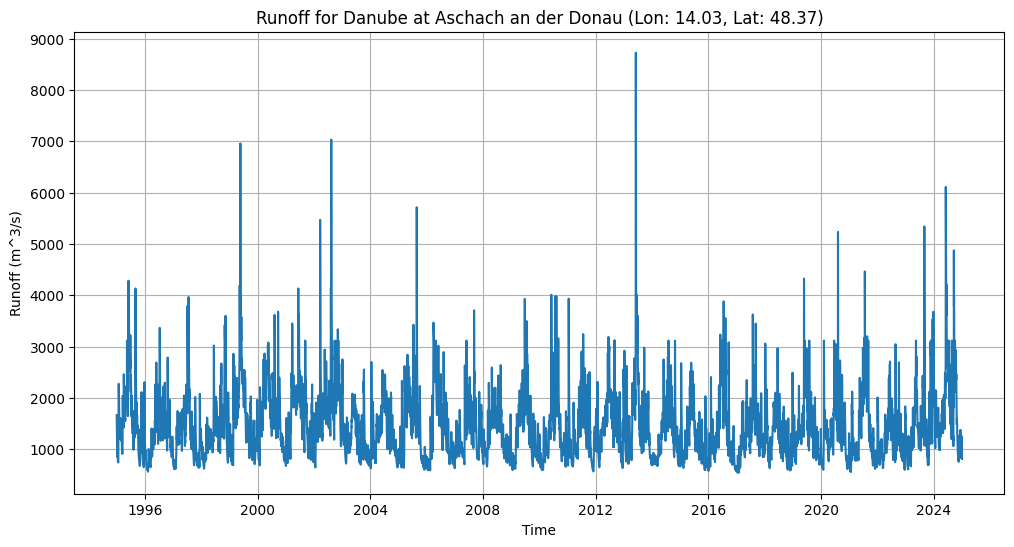

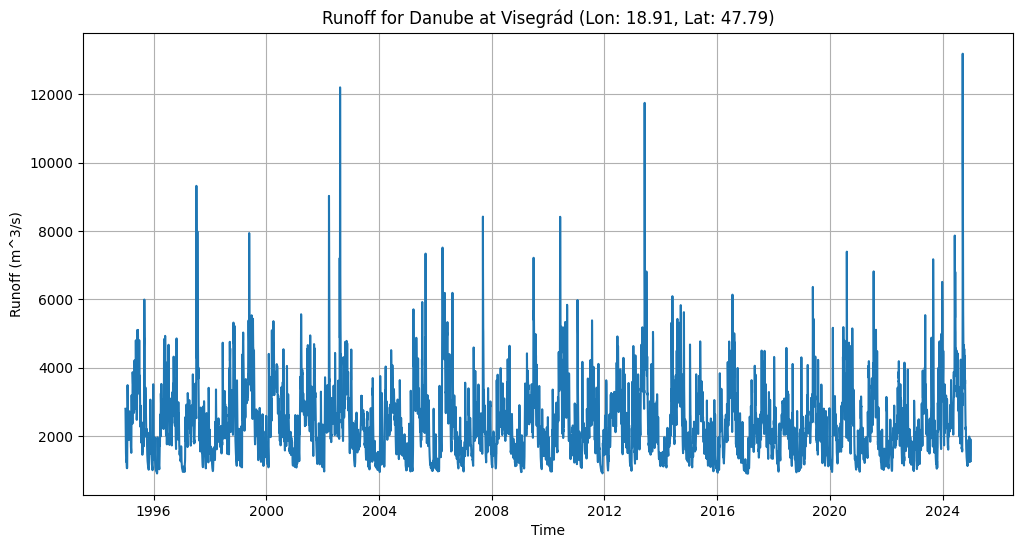

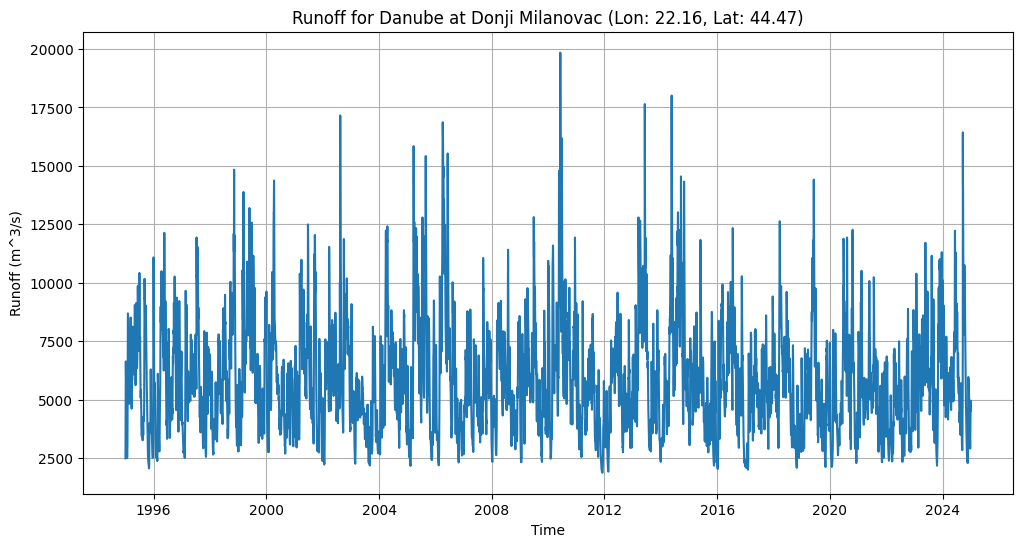

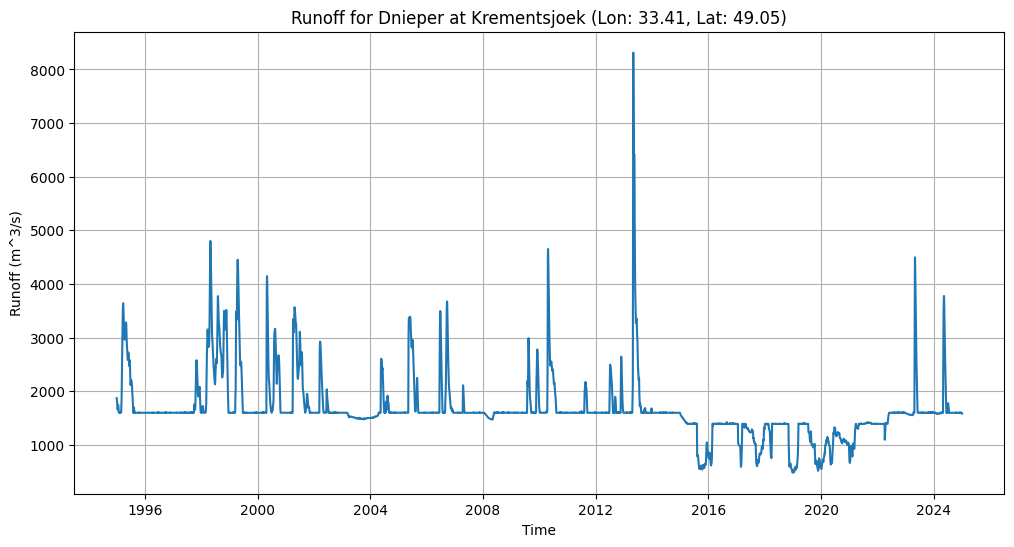

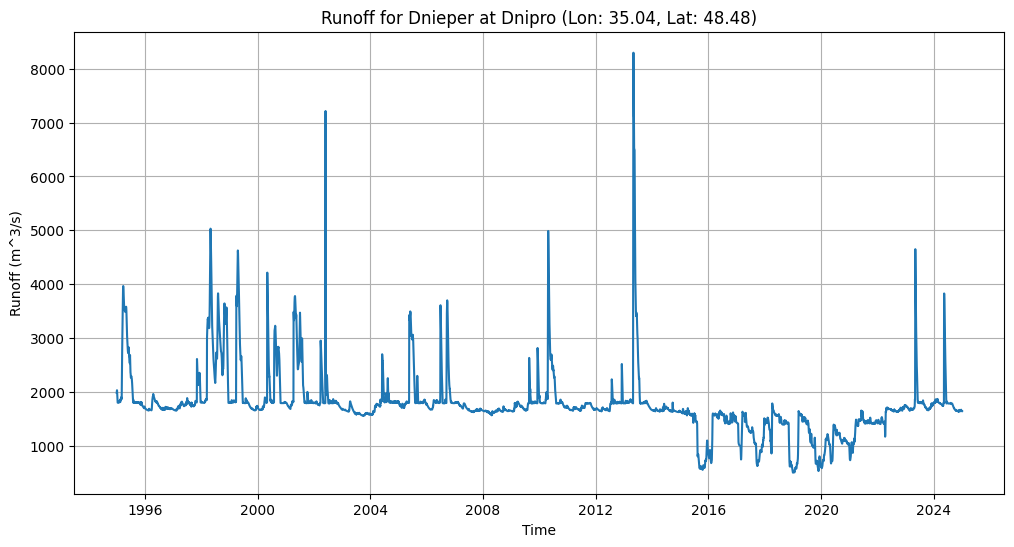

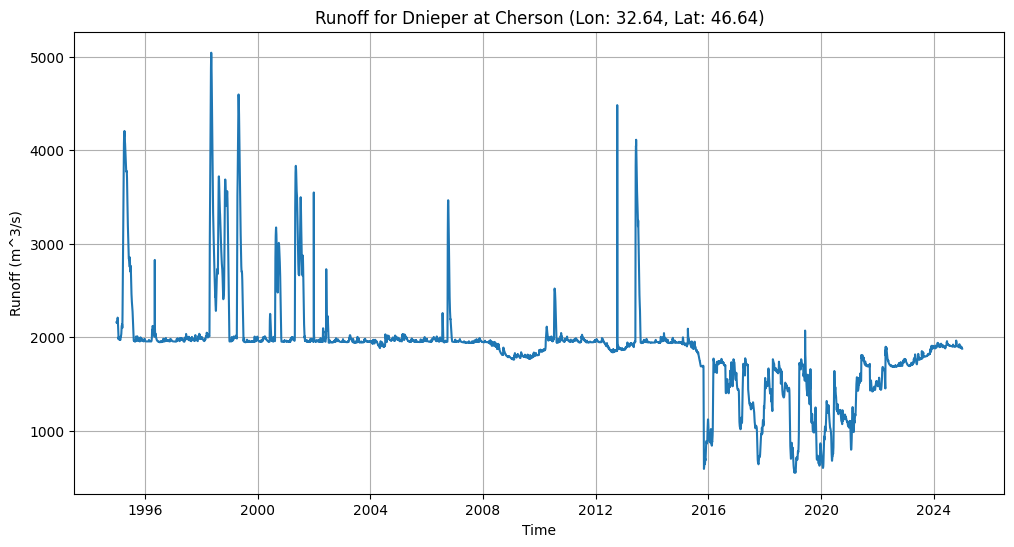

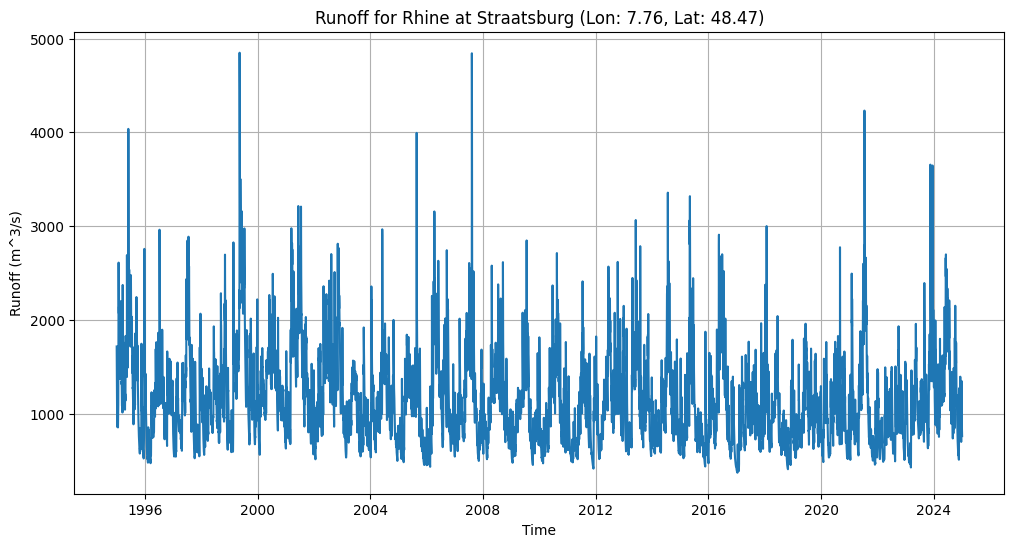

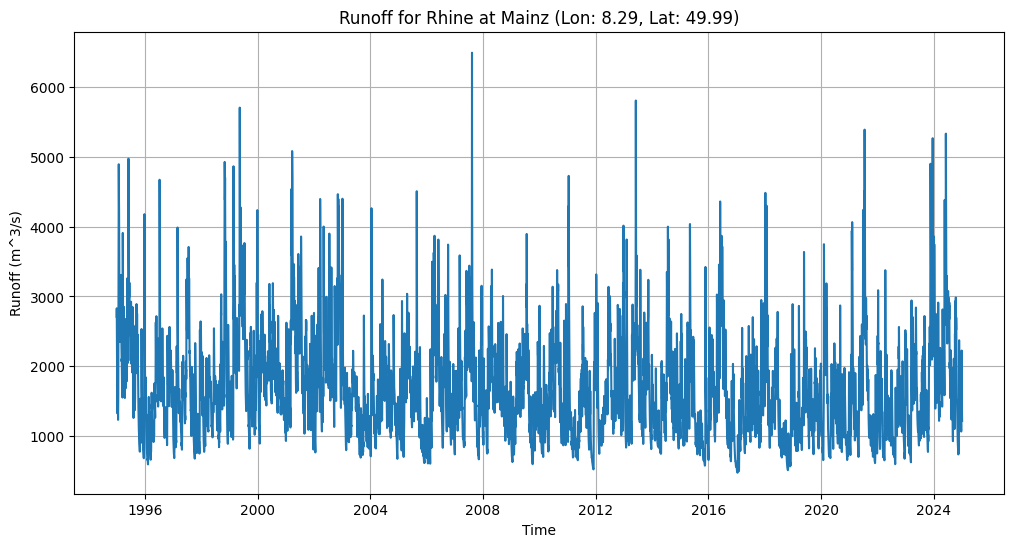

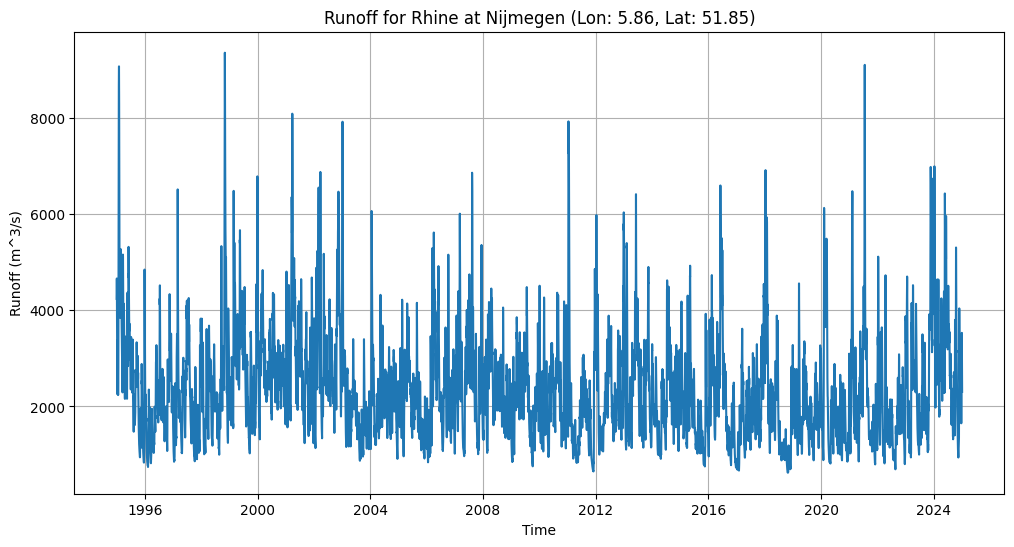

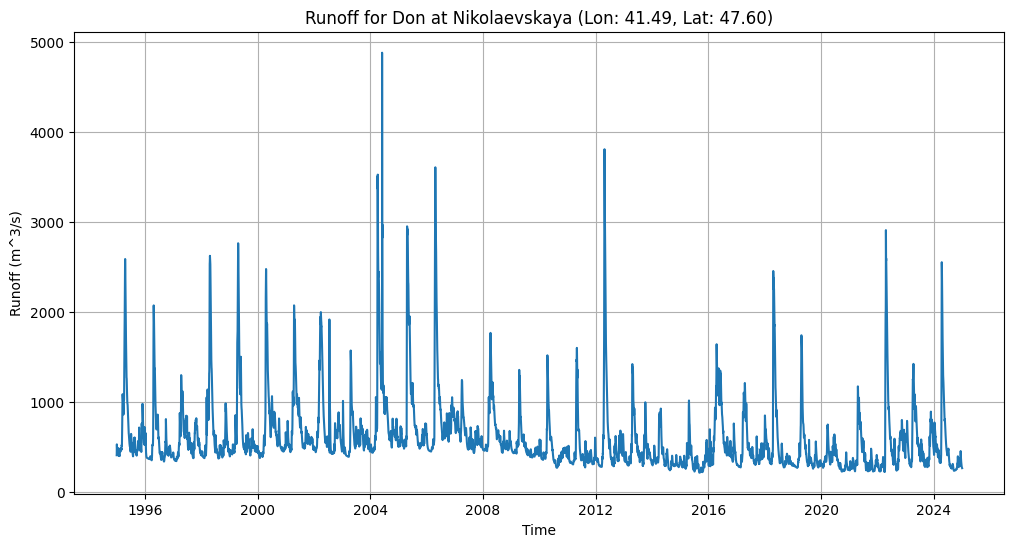

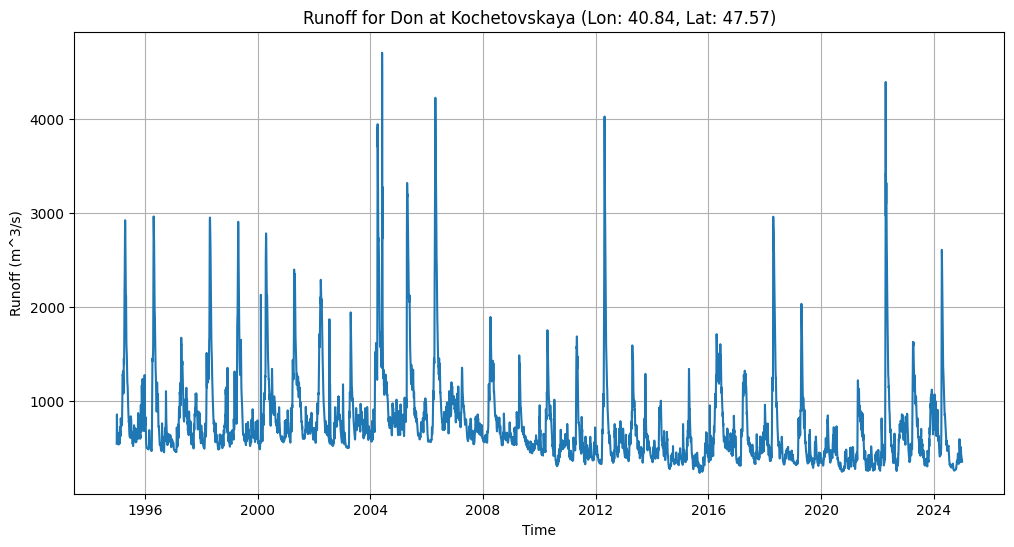

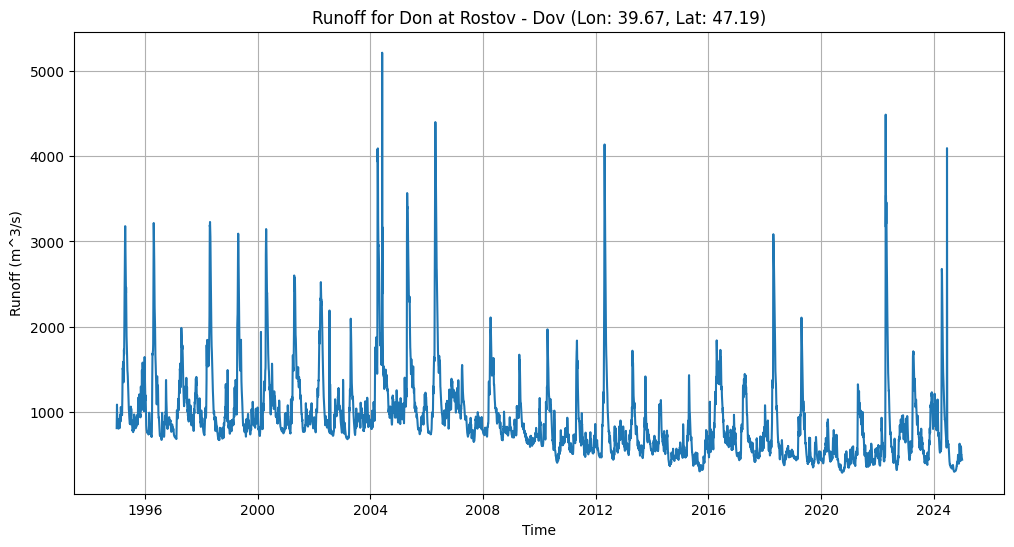

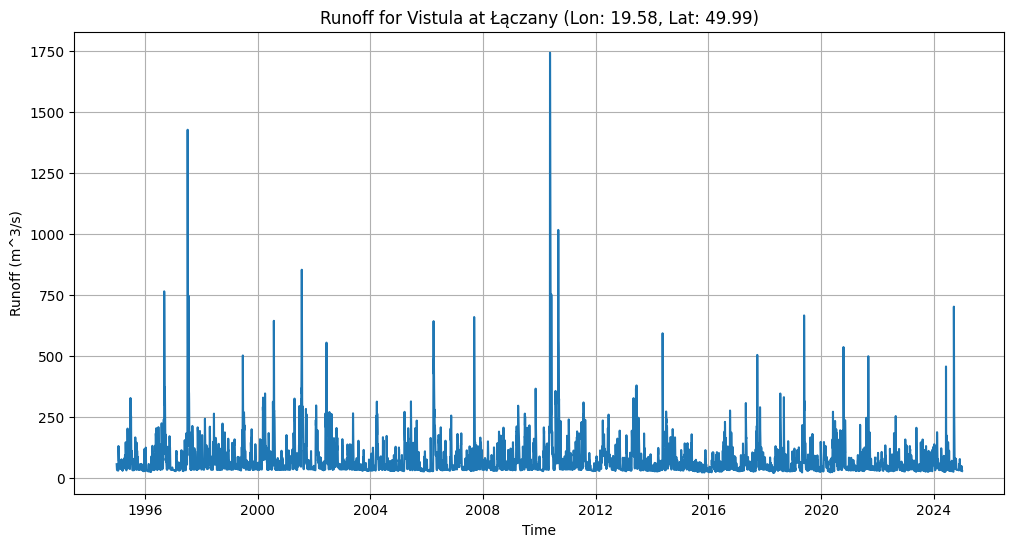

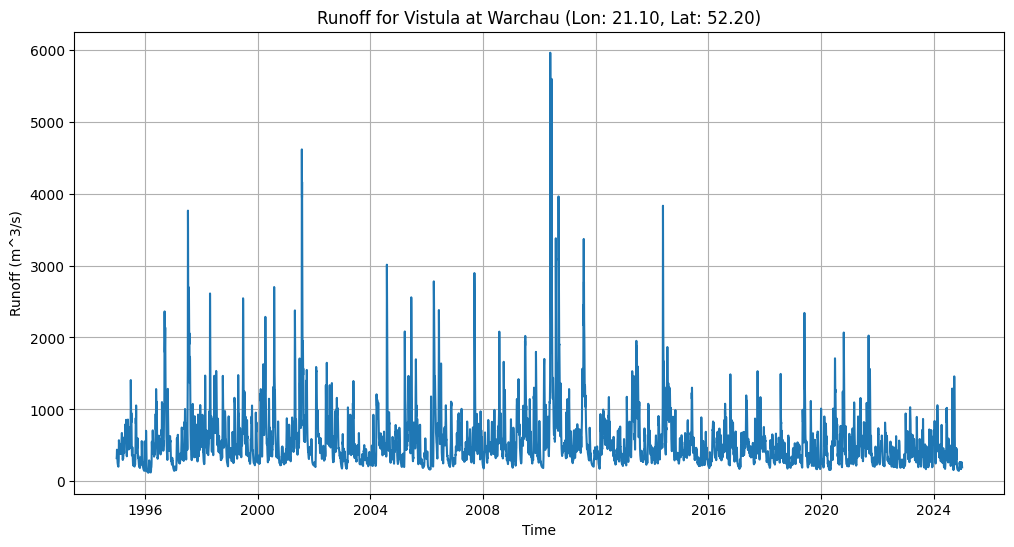

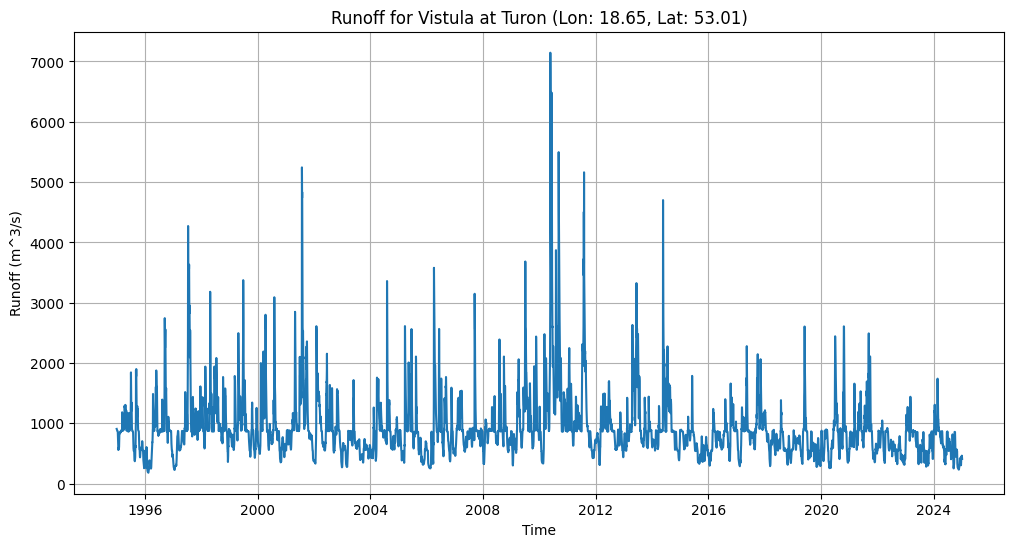

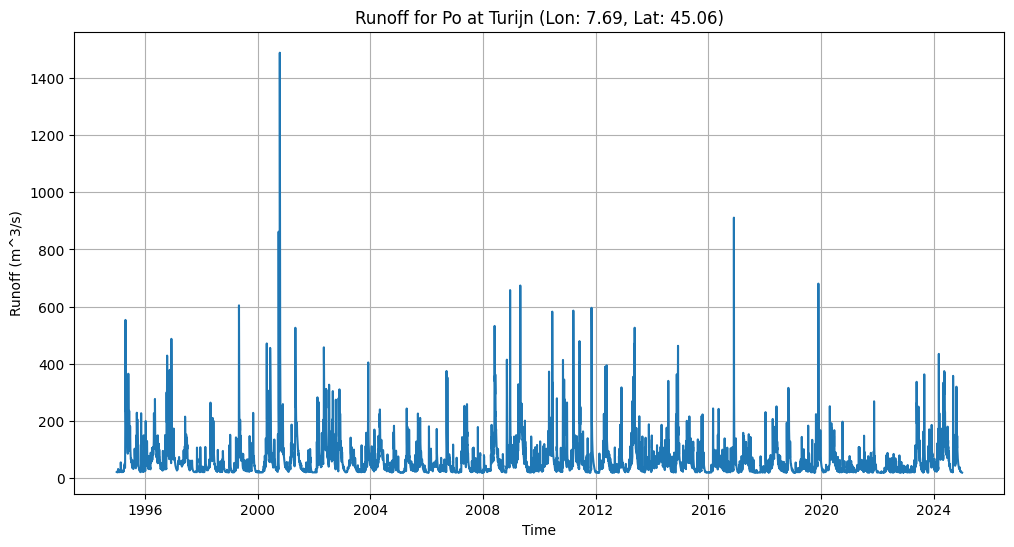

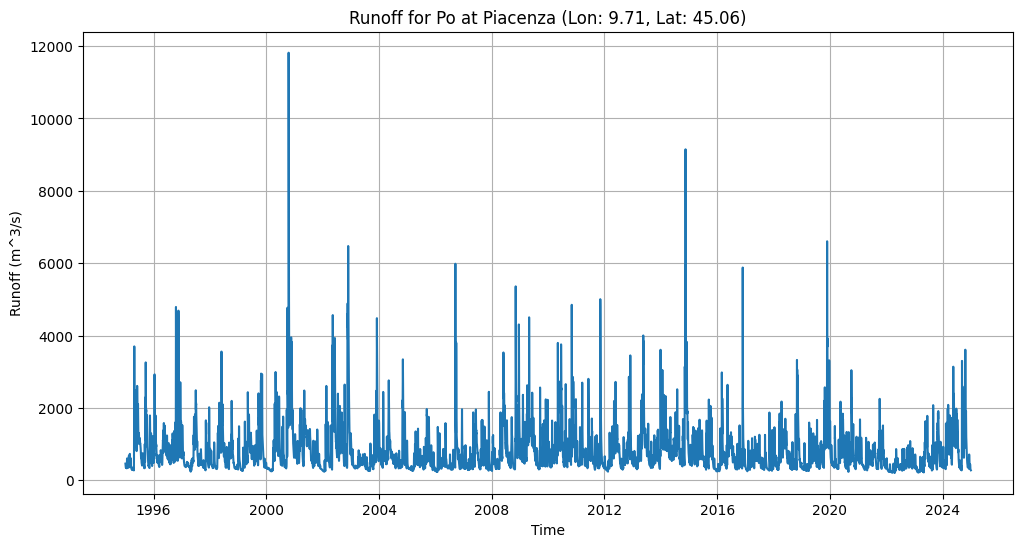

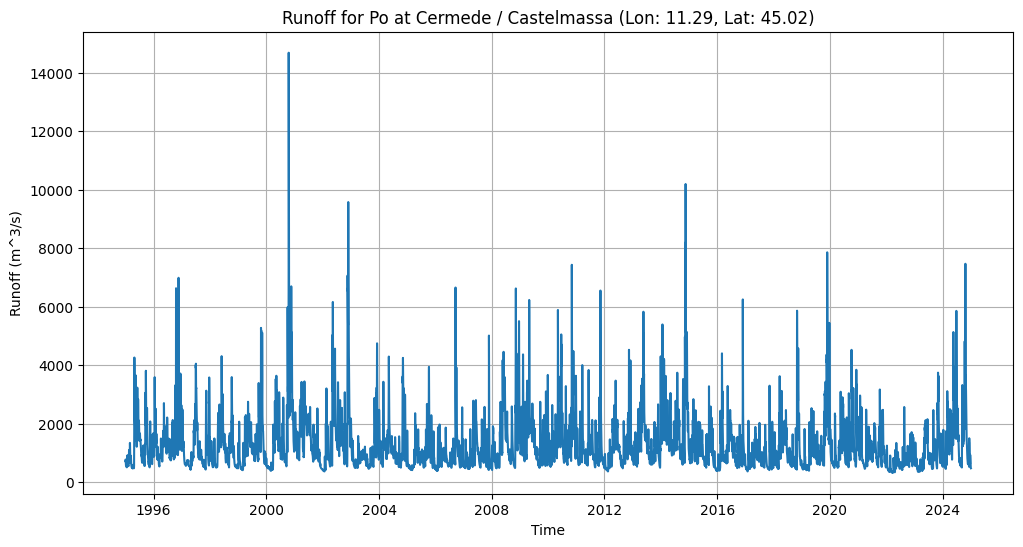

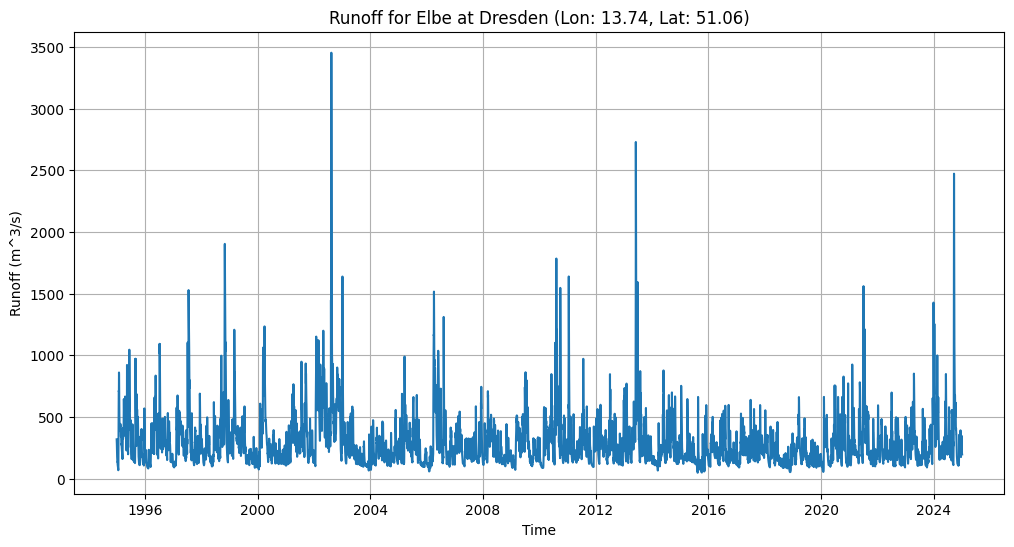

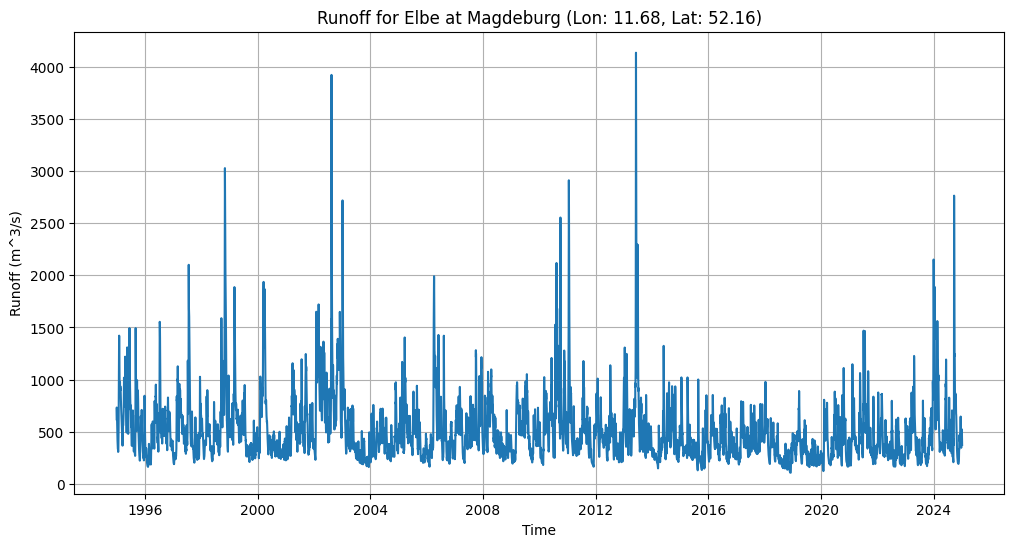

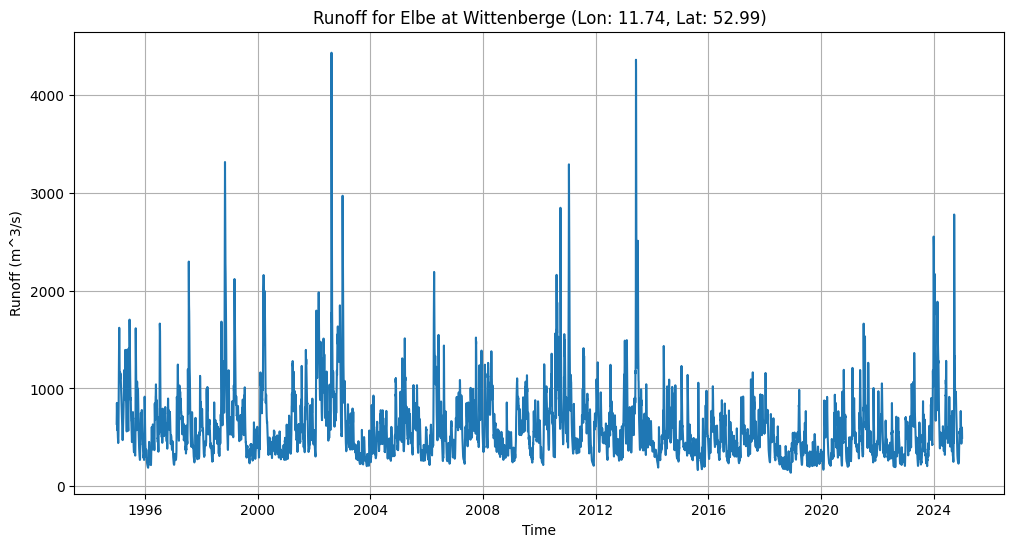

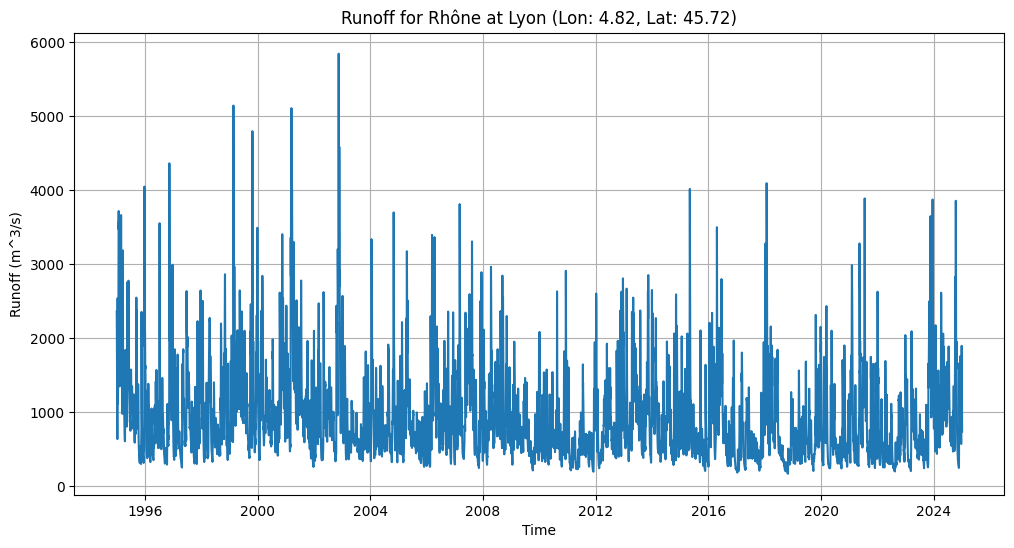

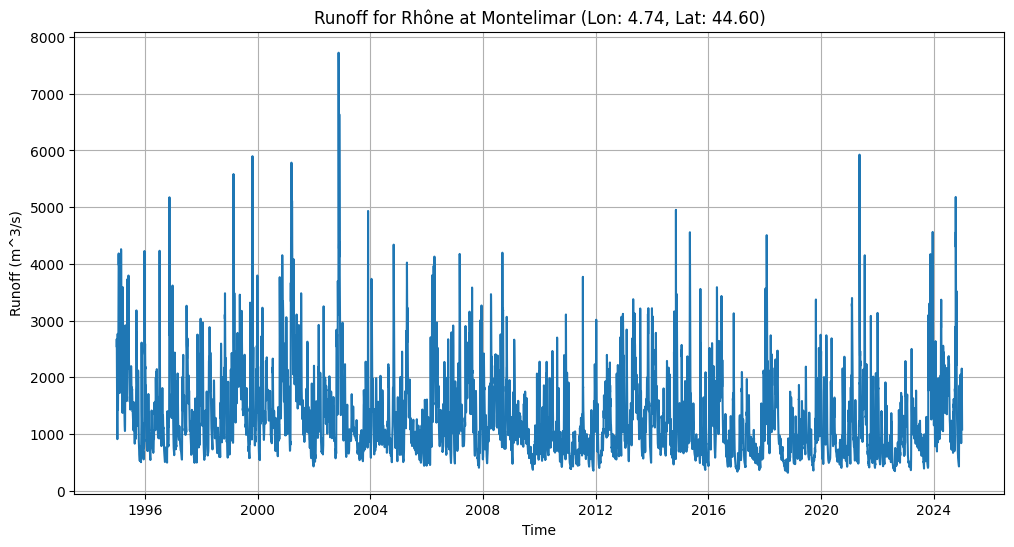

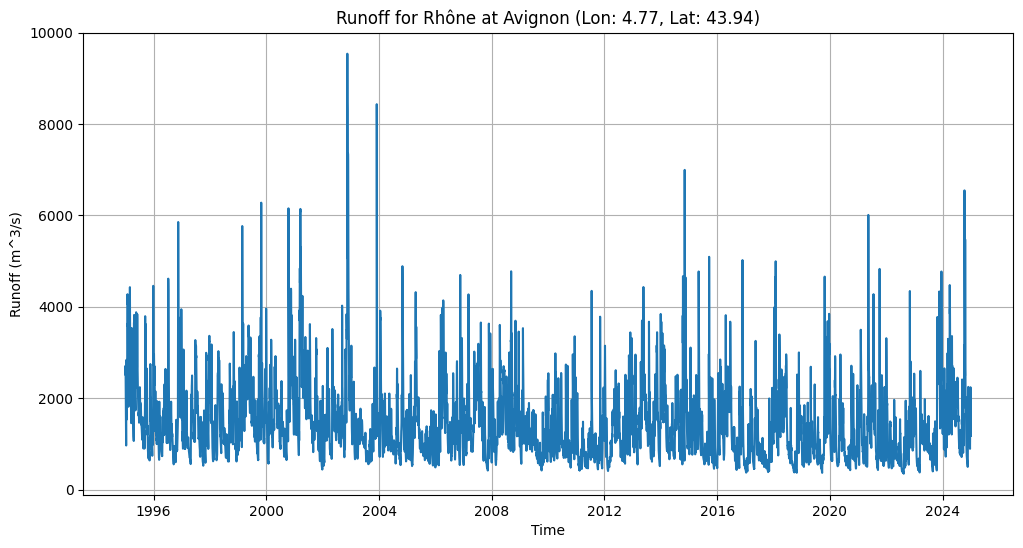

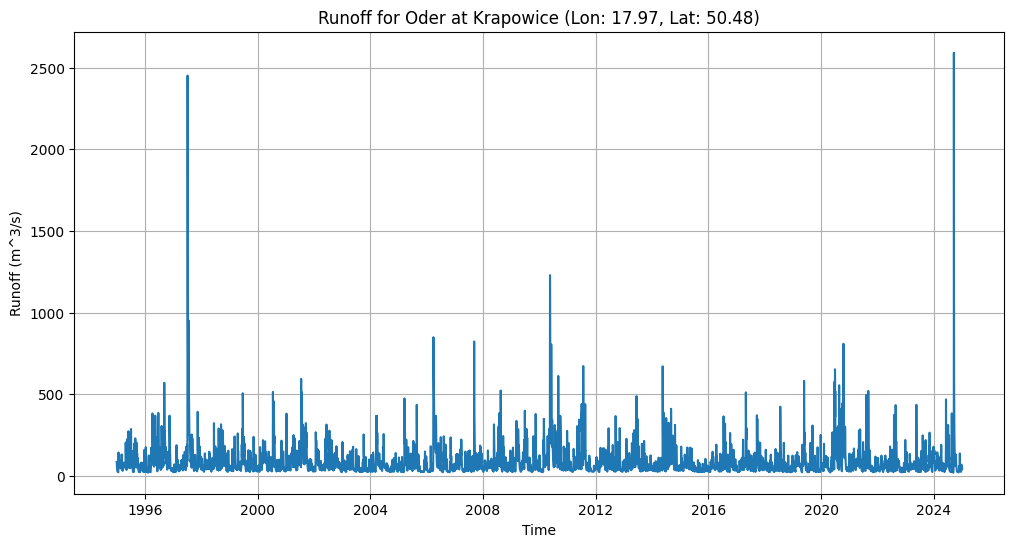

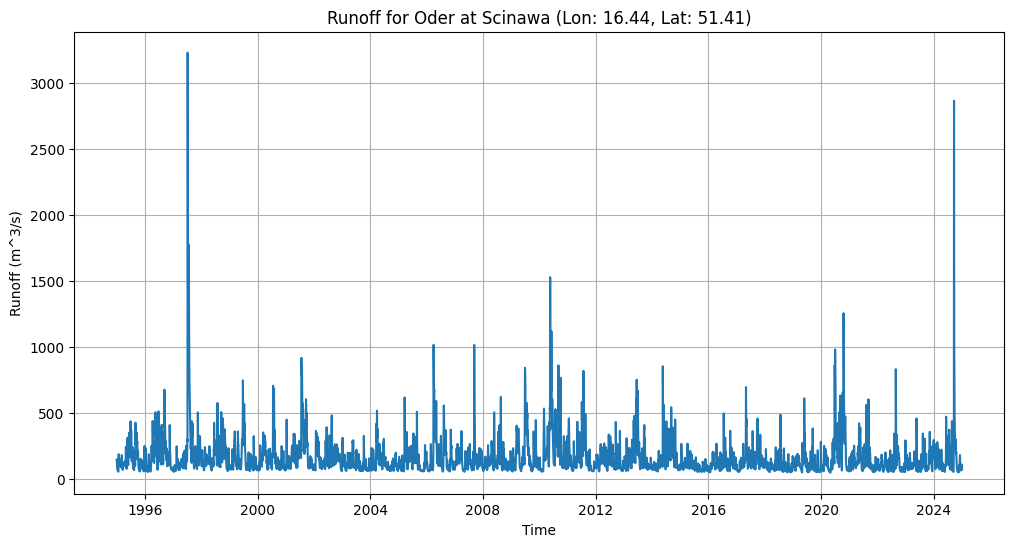

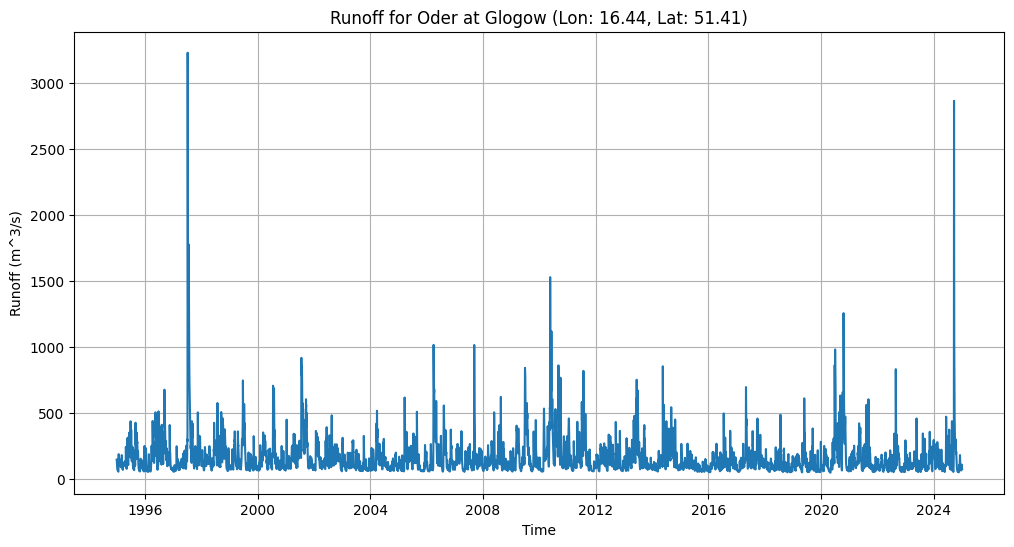

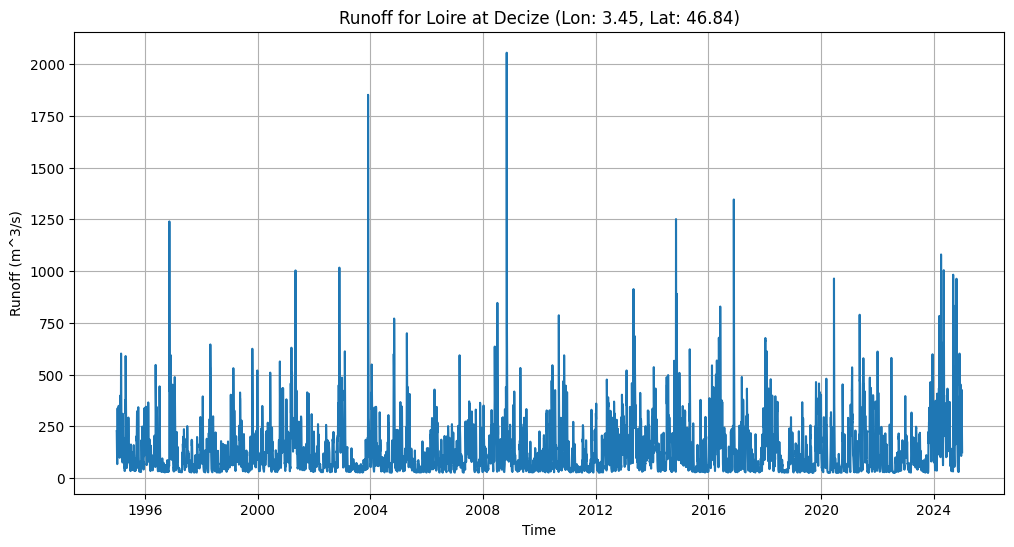

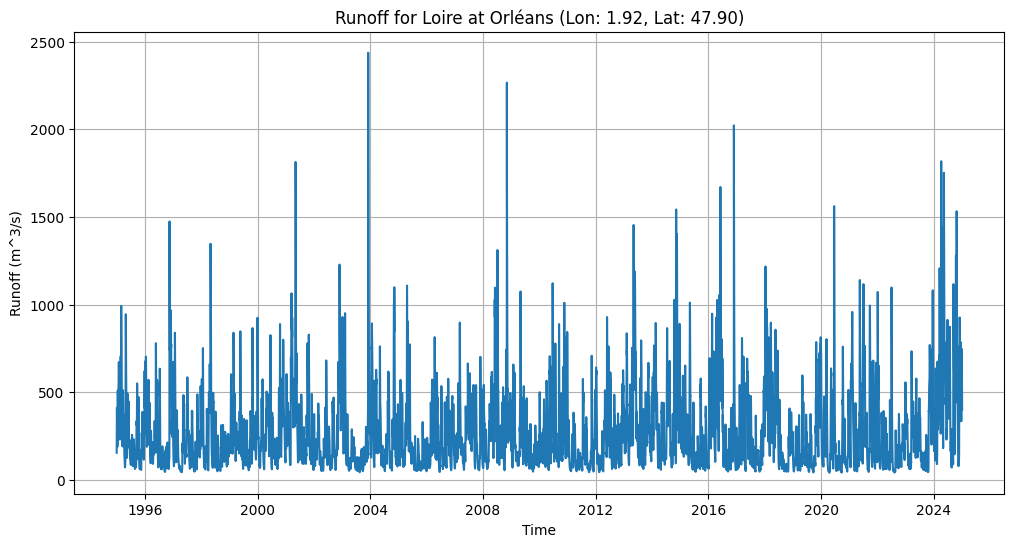

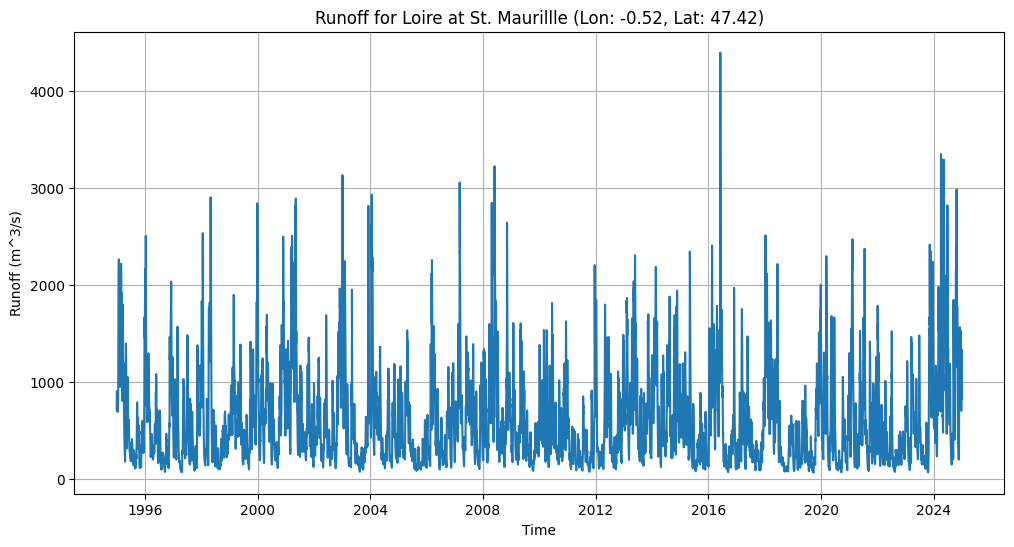

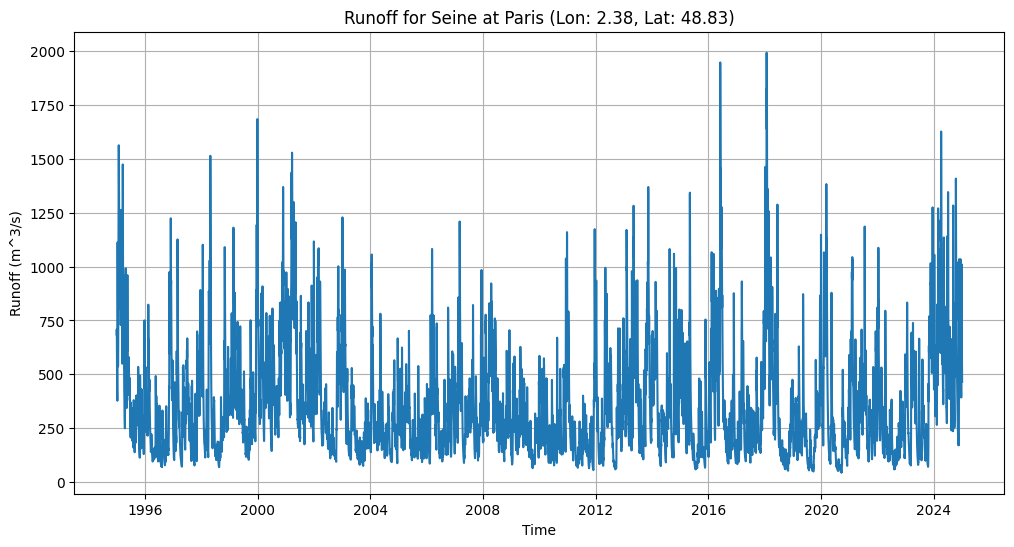

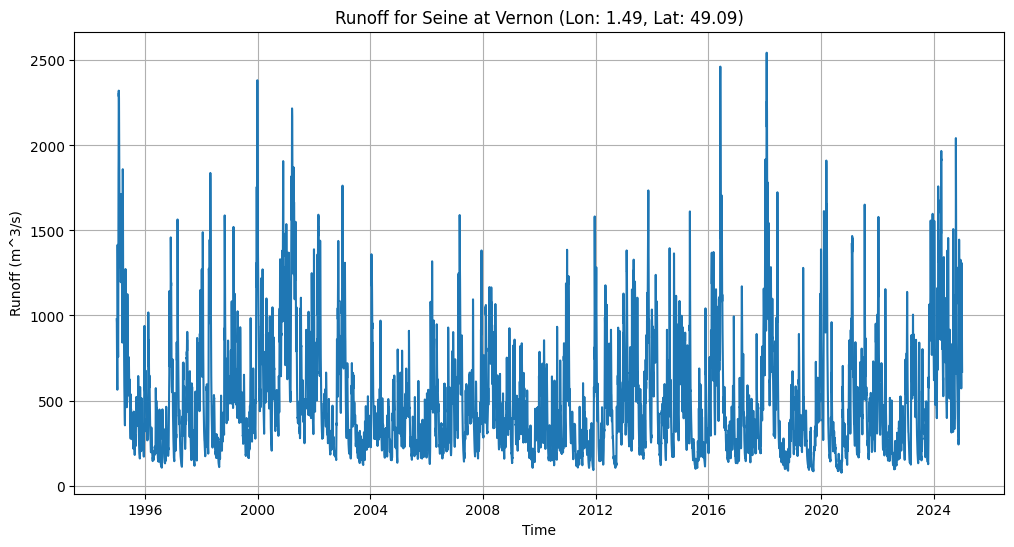

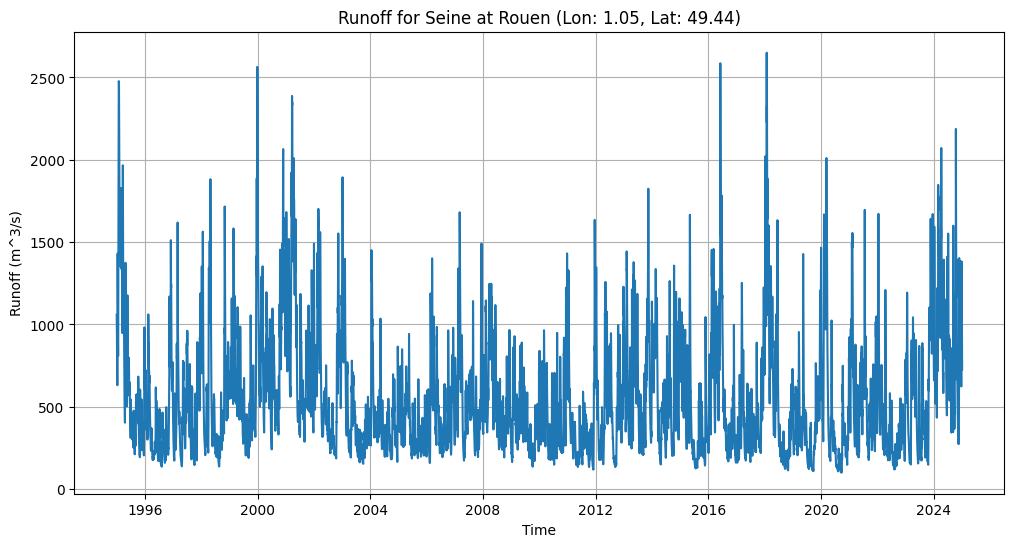

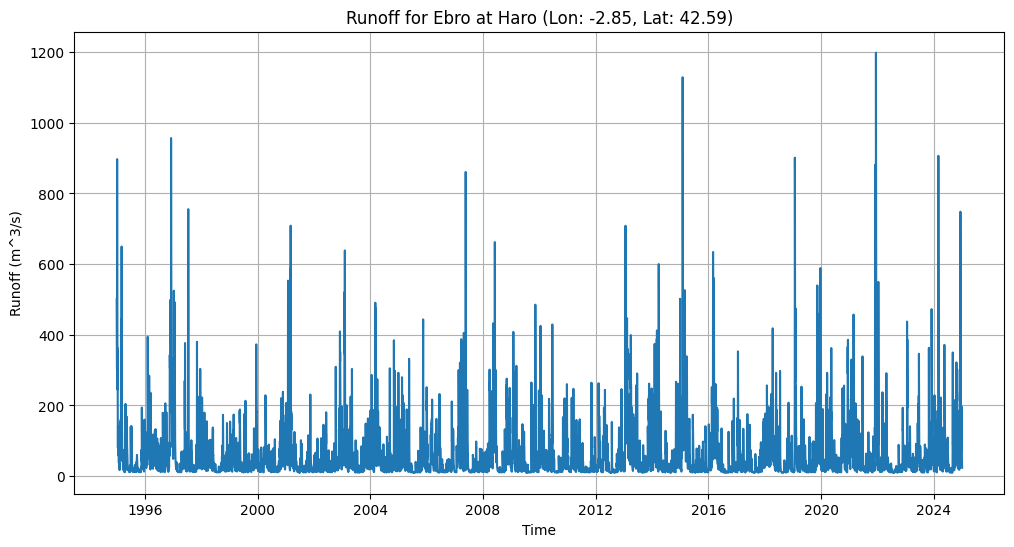

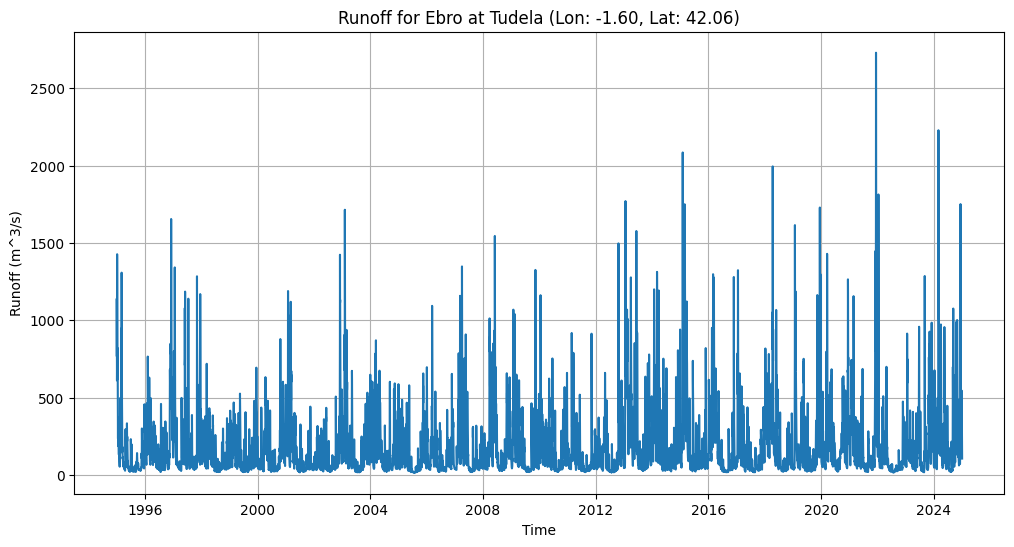

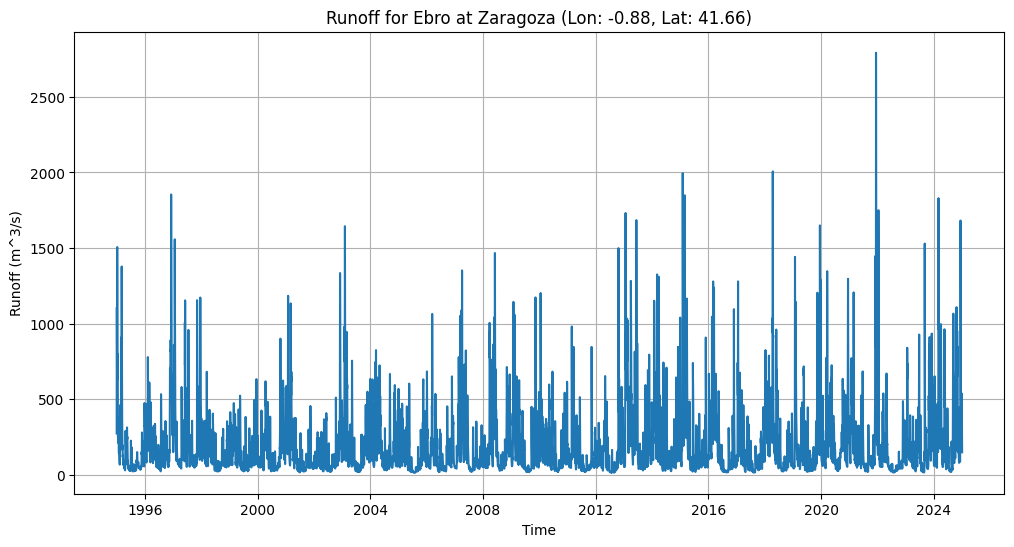

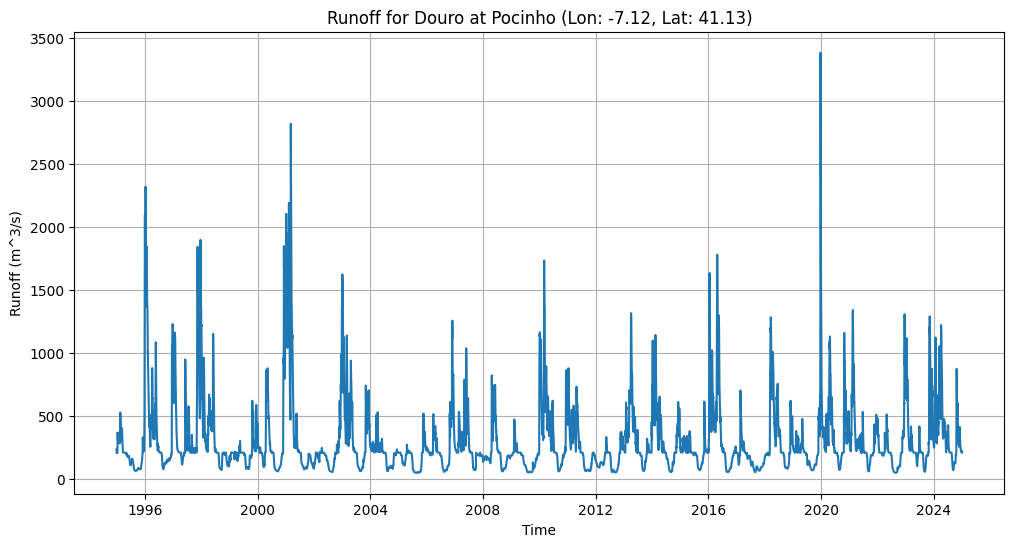

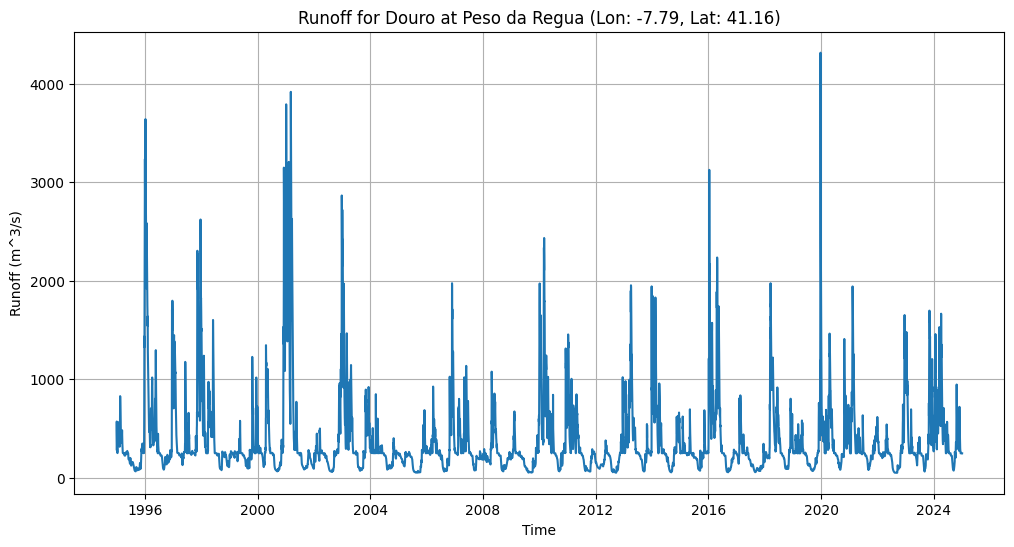

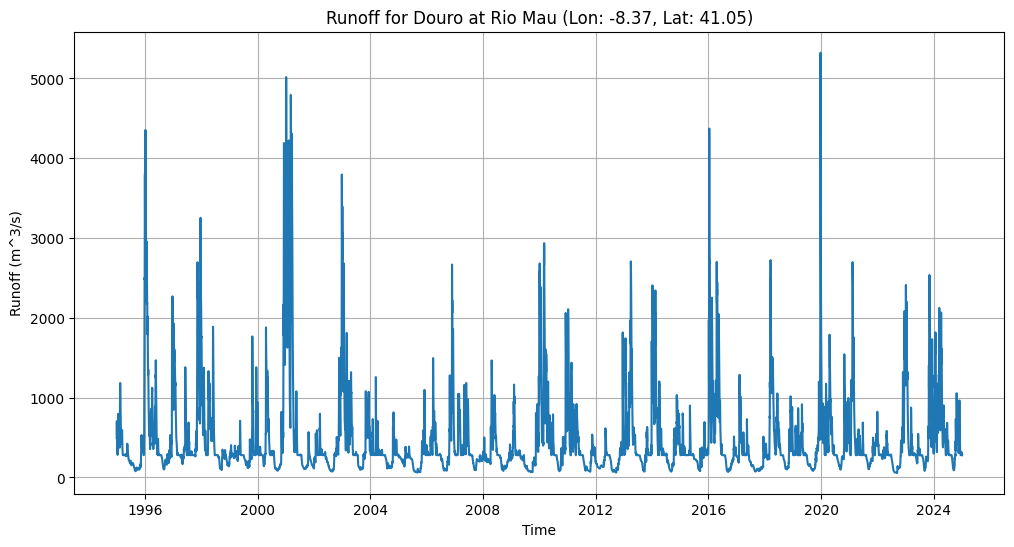

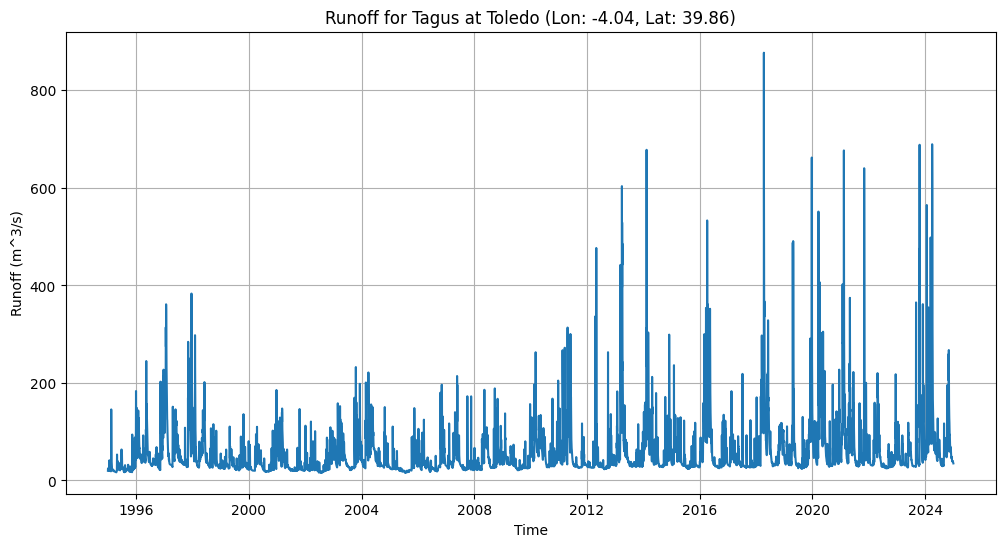

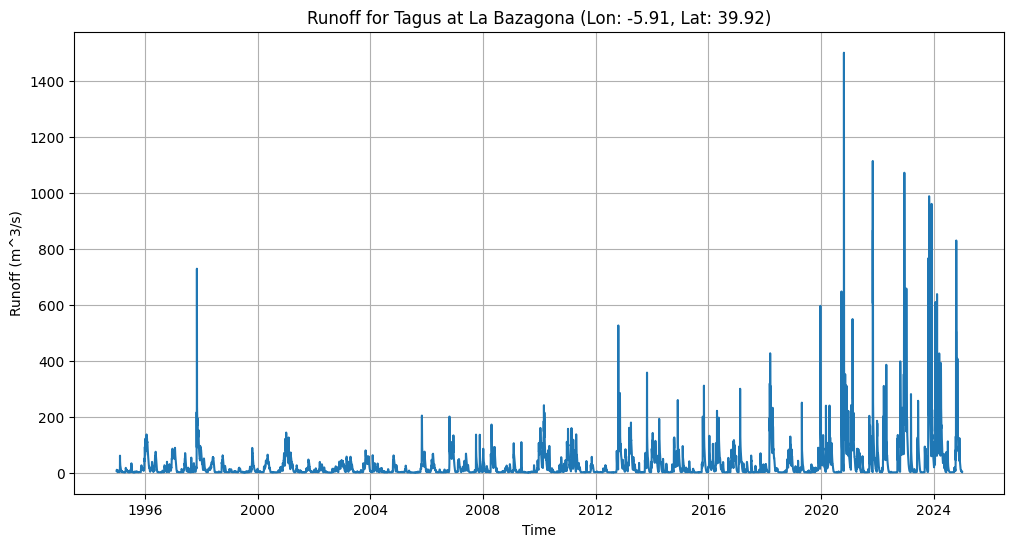

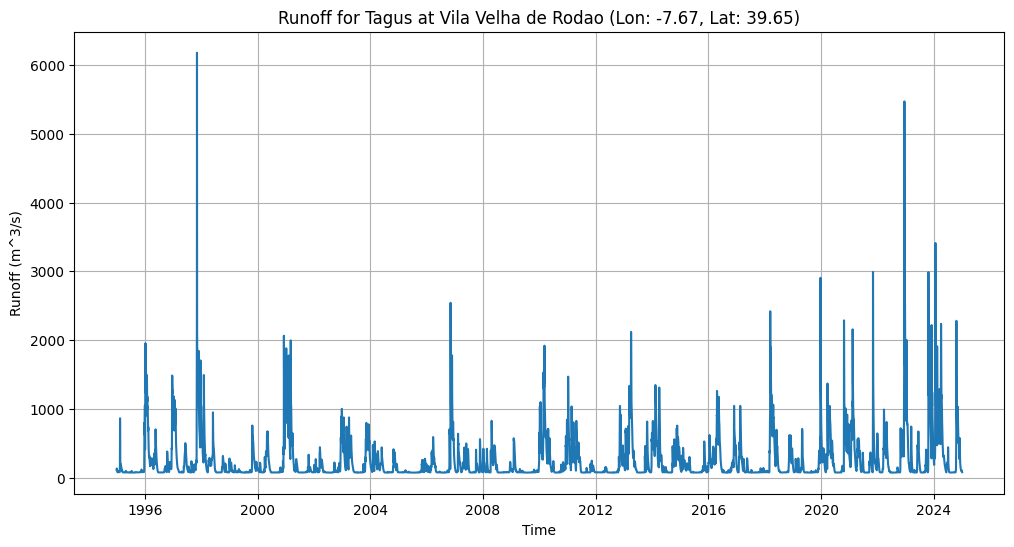

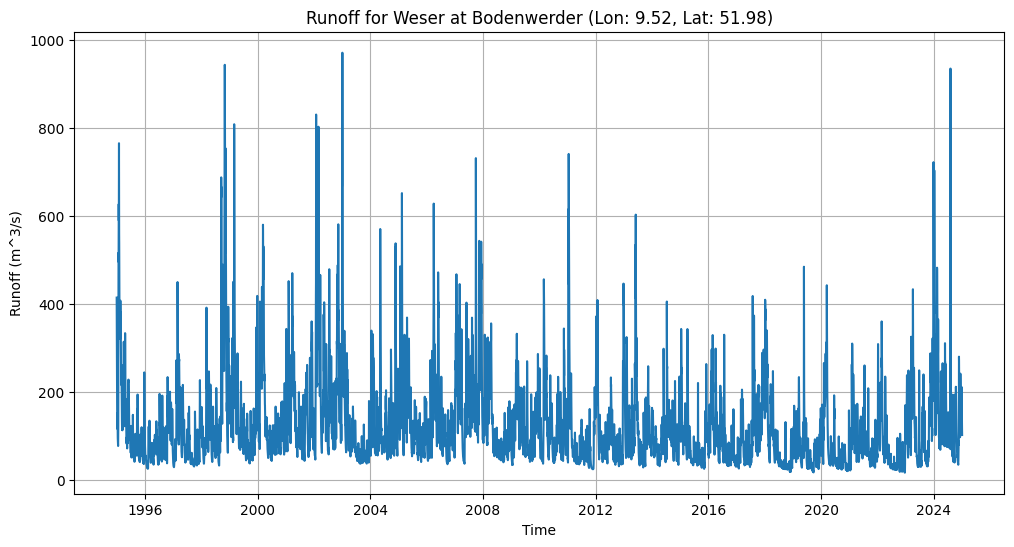

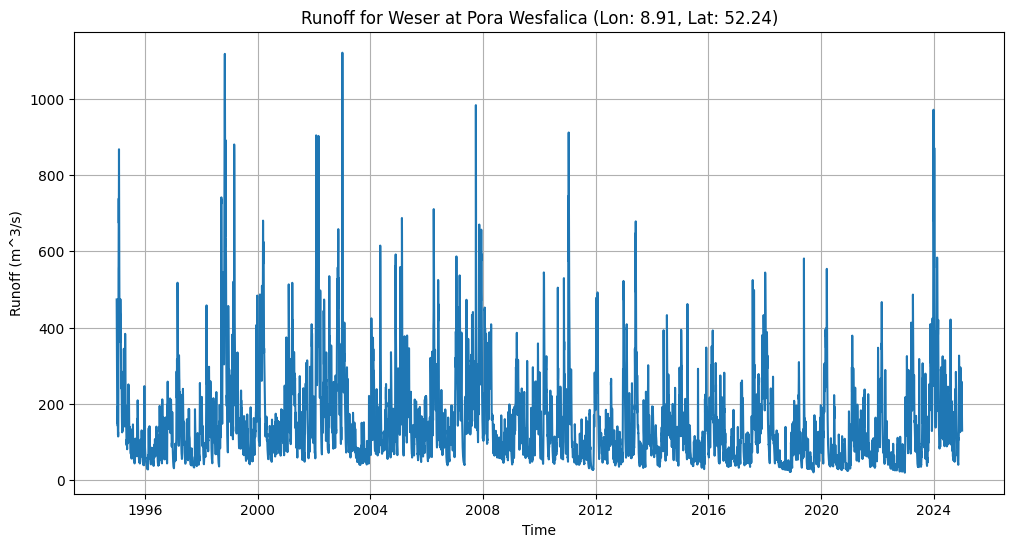

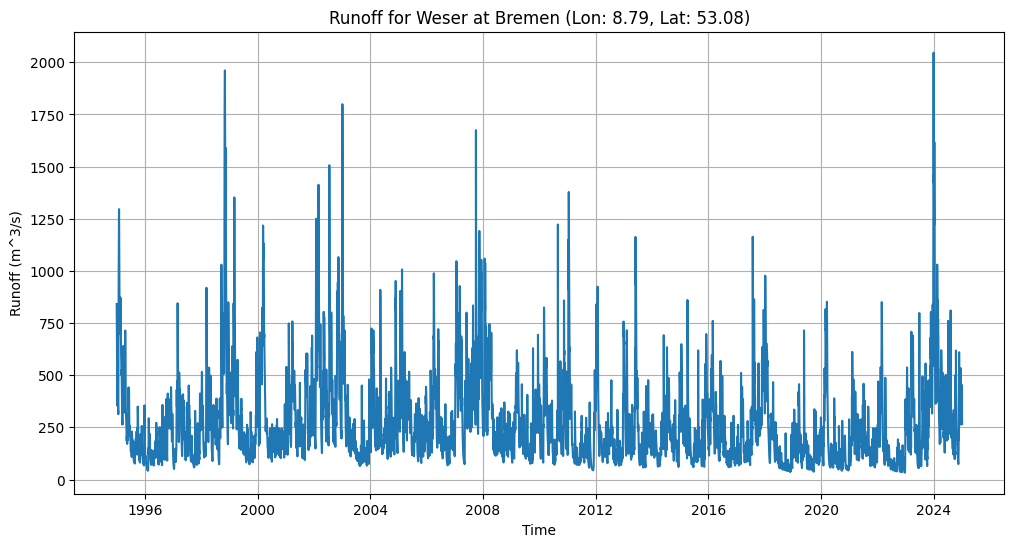

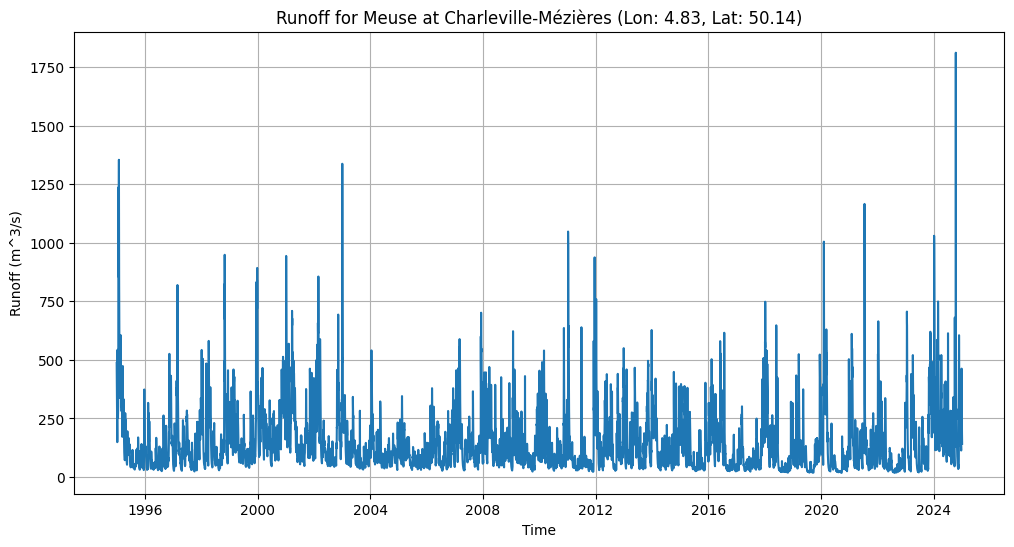

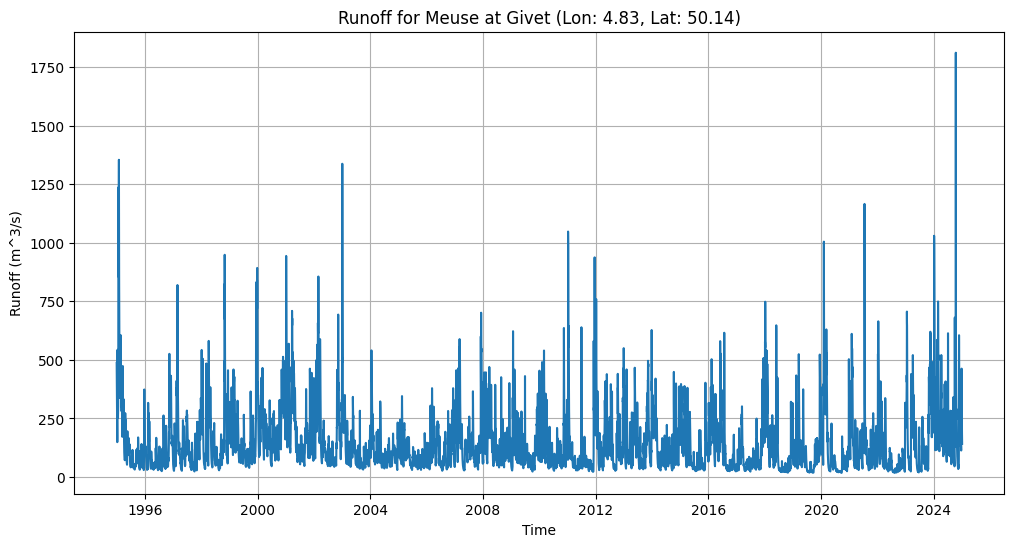

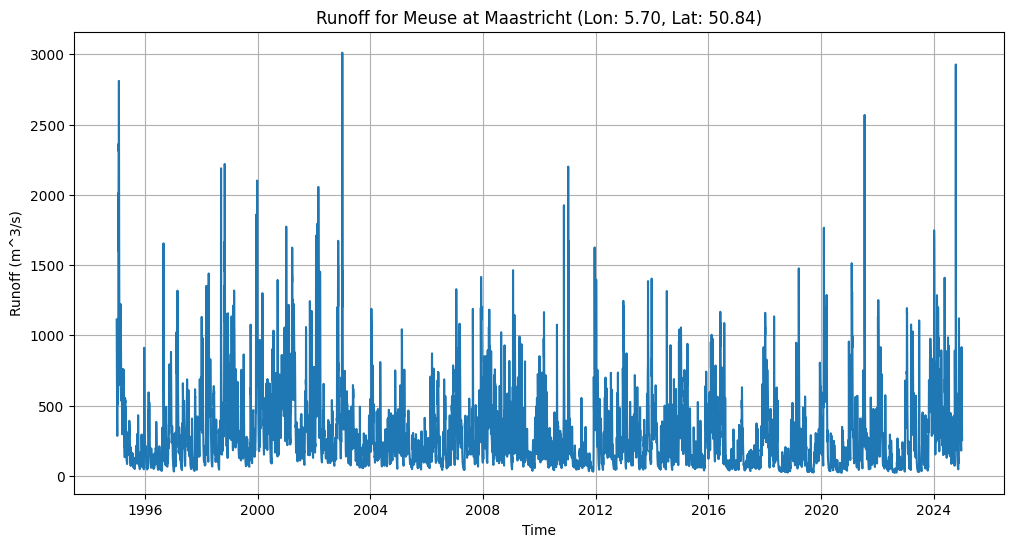

In [ ]:
for river_data in rivers:
    for loc in river_data['locations']:

        sample_river_info_single_location = loc
        sample_river_name = river_data['river']

        # Combine river name with the location info for the function
        river_info_for_plot = {
          'river': sample_river_name,
          'village': sample_river_info_single_location['village'],
          'latitude': sample_river_info_single_location['latitude'],
          'longitude': sample_river_info_single_location['longitude']
        }

        # Call the function to generate the plot
        runoff_plot_fig = plot_location_runoff(data, river_info_for_plot)

        # Display the plot
        plt.show(runoff_plot_fig)

## Final Task

### Subtask:
Confirm that the code has been fixed and executed successfully, displaying runoff plots for all river locations.


## Summary:

### Data Analysis Key Findings
*   The code successfully iterated through all river entries using `for river_data in rivers:`.
*   The inner loop correctly processed all locations associated with each river using `for loc in river_data['locations']:`.
*   For each unique river location, the `plot_location_runoff` function was successfully called with a properly constructed `river_info_for_plot` dictionary.
*   A runoff plot was generated and displayed for every identified river location, indicated by the output `"<Figure size 1200x600 with 1 Axes>"`, confirming the function's correct operation and data passing.

### Insights or Next Steps
*   The successful execution confirms that the syntax issues in the loop and variable referencing have been resolved, and the plotting functionality for all river locations is now fully operational.
